<a href="https://www.kaggle.com/code/lalit7881/global-food-delivery-market-2026-eda?scriptVersionId=366205122" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/luthfimuthathohirin/global-food-delivery-restaurant-market-2026/global_food_delivery_enriched_market_2026.csv


## Loading dataset

In [2]:
df = pd.read_csv("/kaggle/input/datasets/luthfimuthathohirin/global-food-delivery-restaurant-market-2026/global_food_delivery_enriched_market_2026.csv")

In [3]:
df.head()

,order_id,metro_city,cuisine_category,order_channel,order_value_usd,discount_applied_usd,delivery_distance_km,estimated_prep_time_min,actual_delivery_time_min,delivery_fee_usd,...,delivery_speed_km_per_hr,total_fulfillment_time_min,delivery_fee_ratio,customer_spending_tier,logistics_friction_index,estimated_restaurant_net_margin_usd,customer_satisfaction_tier,primary_satisfaction_driver,cot_market_dynamics_rationale,confidence_score
0,ord_02fb1f942abf,Berlin,Burgers & Fast Food,Online Delivery App,20.80,0.00,0.5,14,8.0,2.02,...,3.75,22.0,0.0971,Budget-Saver,0.20,6.20,Neutral-Tolerant-3Star,Rapid-Fulfillment,Pesanan 'ord_02fb1f942abf' di metropolis 'Berl...,0.986
1,ord_0337e00c92a2,Berlin,Burgers & Fast Food,Online Delivery App,3.50,1.20,0.9,24,8.0,3.31,...,6.75,32.0,0.9457,Occasional-Promo-Seeker,4.18,-0.21,Satisfied-4Star,High-Value-Discounting,Pesanan 'ord_0337e00c92a2' di metropolis 'Berl...,0.988
2,ord_0384f1e25fed,Berlin,Burgers & Fast Food,Takeaway / Pickup,13.12,1.46,0.0,13,0.0,0.00,...,0.00,13.0,0.0000,Budget-Saver,0.20,4.31,Neutral-Tolerant-3Star,Rapid-Fulfillment,Pesanan 'ord_0384f1e25fed' di metropolis 'Berl...,0.986
3,ord_0406c3fd20e4,Berlin,Burgers & Fast Food,Takeaway / Pickup,10.54,1.32,0.0,15,0.0,0.00,...,0.00,15.0,0.0000,Budget-Saver,1.50,3.23,Delighted-5Star,Rapid-Fulfillment,Pesanan 'ord_0406c3fd20e4' di metropolis 'Berl...,0.989
4,ord_059fca6f1251,Berlin,Burgers & Fast Food,Online Delivery App,121.46,9.06,0.8,15,8.0,3.02,...,6.00,23.0,0.0249,High-Roller-Gourmet,3.94,43.44,Satisfied-4Star,Rapid-Fulfillment,Pesanan 'ord_059fca6f1251' di metropolis 'Berl...,0.989


In [4]:
df.tail()

,order_id,metro_city,cuisine_category,order_channel,order_value_usd,discount_applied_usd,delivery_distance_km,estimated_prep_time_min,actual_delivery_time_min,delivery_fee_usd,...,delivery_speed_km_per_hr,total_fulfillment_time_min,delivery_fee_ratio,customer_spending_tier,logistics_friction_index,estimated_restaurant_net_margin_usd,customer_satisfaction_tier,primary_satisfaction_driver,cot_market_dynamics_rationale,confidence_score
7995,ord_d5749dc3b77a,Toronto,Mexican & Tacos,Online Delivery App,26.04,7.07,9.1,20,21.5,5.89,...,25.40,41.5,0.2262,Occasional-Promo-Seeker,1.64,8.13,Delighted-5Star,High-Value-Discounting,Pesanan 'ord_d5749dc3b77a' di metropolis 'Toro...,0.989
7996,ord_ede00eb132fa,Toronto,Mexican & Tacos,Online Delivery App,9.29,0.00,1.5,18,8.0,2.48,...,11.25,26.0,0.2670,Budget-Saver,0.27,1.94,Delighted-5Star,Rapid-Fulfillment,Pesanan 'ord_ede00eb132fa' di metropolis 'Toro...,0.989
7997,ord_f4efefd229a1,Toronto,Mexican & Tacos,Dine-In POS,82.65,15.54,0.0,15,0.0,0.00,...,0.00,15.0,0.0000,High-Roller-Gourmet,3.70,38.55,Satisfied-4Star,High-Value-Discounting,Pesanan 'ord_f4efefd229a1' di metropolis 'Toro...,0.988
7998,ord_f9558a4cd83b,Toronto,Mexican & Tacos,Online Delivery App,32.47,7.51,16.1,15,40.1,9.05,...,24.09,55.1,0.2787,Mid-Tier-Regular,2.50,10.51,Neutral-Tolerant-3Star,Overpriced-Delivery-Fee,Pesanan 'ord_f9558a4cd83b' di metropolis 'Toro...,0.987
7999,ord_fb775177b74a,Toronto,Mexican & Tacos,Dine-In POS,3.50,0.00,0.0,22,0.0,0.00,...,0.00,22.0,0.0000,Budget-Saver,1.66,1.35,Satisfied-4Star,Quality-Food-Packaging,Pesanan 'ord_fb775177b74a' di metropolis 'Toro...,0.989


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 26 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   order_id                             8000 non-null   object 
 1   metro_city                           8000 non-null   object 
 2   cuisine_category                     8000 non-null   object 
 3   order_channel                        8000 non-null   object 
 4   order_value_usd                      8000 non-null   float64
 5   discount_applied_usd                 8000 non-null   float64
 6   delivery_distance_km                 8000 non-null   float64
 7   estimated_prep_time_min              8000 non-null   int64  
 8   actual_delivery_time_min             8000 non-null   float64
 9   delivery_fee_usd                     8000 non-null   float64
 10  customer_rating                      8000 non-null   float64
 11  restaurant_price_tier         

In [6]:
df.describe()

,order_value_usd,discount_applied_usd,delivery_distance_km,estimated_prep_time_min,actual_delivery_time_min,delivery_fee_usd,customer_rating,net_effective_order_price,discount_percentage,delivery_speed_km_per_hr,total_fulfillment_time_min,delivery_fee_ratio,logistics_friction_index,estimated_restaurant_net_margin_usd,confidence_score
count,8000.000000,8000.000000,8000.000000,8000.00000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,30.222839,3.328607,3.048638,18.04200,11.272588,2.962597,4.281375,29.856829,11.911265,10.287050,29.314588,0.184009,2.251100,10.789798,0.987976
std,26.366910,5.183003,3.937749,6.76934,13.533084,2.672989,0.647210,24.372821,12.115306,9.335752,16.210216,0.270723,1.624059,10.667783,0.002500
min,3.500000,0.000000,0.000000,5.00000,0.000000,0.000000,1.000000,2.300000,0.000000,0.000000,5.000000,0.000000,0.200000,-0.210000,0.953000
25%,12.920000,0.000000,0.000000,13.00000,0.000000,0.000000,4.000000,14.040000,0.000000,0.000000,18.000000,0.000000,0.850000,3.727500,0.988000
50%,21.705000,1.530000,1.600000,18.00000,8.000000,2.970000,4.500000,22.310000,9.535000,10.500000,26.000000,0.100850,2.190000,7.440000,0.989000
75%,37.892500,4.440000,4.500000,22.00000,15.200000,4.540000,5.000000,37.235000,23.022500,17.050000,36.700000,0.249425,3.300000,13.912500,0.989000
max,145.000000,35.000000,22.000000,49.00000,75.000000,9.500000,5.000000,154.500000,35.020000,57.000000,111.000000,2.714300,8.920000,67.850000,0.990000


In [7]:
df.isnull().sum()

order_id                               0
metro_city                             0
cuisine_category                       0
order_channel                          0
order_value_usd                        0
discount_applied_usd                   0
delivery_distance_km                   0
estimated_prep_time_min                0
actual_delivery_time_min               0
delivery_fee_usd                       0
customer_rating                        0
restaurant_price_tier                  0
is_peak_hour                           0
weather_condition                      0
net_effective_order_price              0
discount_percentage                    0
delivery_speed_km_per_hr               0
total_fulfillment_time_min             0
delivery_fee_ratio                     0
customer_spending_tier                 0
logistics_friction_index               0
estimated_restaurant_net_margin_usd    0
customer_satisfaction_tier             0
primary_satisfaction_driver            0
cot_market_dynam

In [8]:
df.duplicated().sum(
)

np.int64(0)

In [9]:
df.dtypes

order_id                                object
metro_city                              object
cuisine_category                        object
order_channel                           object
order_value_usd                        float64
discount_applied_usd                   float64
delivery_distance_km                   float64
estimated_prep_time_min                  int64
actual_delivery_time_min               float64
delivery_fee_usd                       float64
customer_rating                        float64
restaurant_price_tier                   object
is_peak_hour                              bool
weather_condition                       object
net_effective_order_price              float64
discount_percentage                    float64
delivery_speed_km_per_hr               float64
total_fulfillment_time_min             float64
delivery_fee_ratio                     float64
customer_spending_tier                  object
logistics_friction_index               float64
estimated_res

In [10]:
df.shape

(8000, 26)

In [11]:
df.columns

Index(['order_id', 'metro_city', 'cuisine_category', 'order_channel',
       'order_value_usd', 'discount_applied_usd', 'delivery_distance_km',
       'estimated_prep_time_min', 'actual_delivery_time_min',
       'delivery_fee_usd', 'customer_rating', 'restaurant_price_tier',
       'is_peak_hour', 'weather_condition', 'net_effective_order_price',
       'discount_percentage', 'delivery_speed_km_per_hr',
       'total_fulfillment_time_min', 'delivery_fee_ratio',
       'customer_spending_tier', 'logistics_friction_index',
       'estimated_restaurant_net_margin_usd', 'customer_satisfaction_tier',
       'primary_satisfaction_driver', 'cot_market_dynamics_rationale',
       'confidence_score'],
      dtype='object')

In [12]:
df.nunique()

order_id                               8000
metro_city                               12
cuisine_category                          7
order_channel                             3
order_value_usd                        4323
discount_applied_usd                   1343
delivery_distance_km                    202
estimated_prep_time_min                  41
actual_delivery_time_min                515
delivery_fee_usd                        426
customer_rating                           9
restaurant_price_tier                     3
is_peak_hour                              2
weather_condition                         4
net_effective_order_price              4348
discount_percentage                    2414
delivery_speed_km_per_hr               1650
total_fulfillment_time_min              681
delivery_fee_ratio                     3395
customer_spending_tier                    4
logistics_friction_index                674
estimated_restaurant_net_margin_usd    2685
customer_satisfaction_tier      

## EDA

FOOD DELIVERY DATASET - EXPLORATORY DATA ANALYSIS

Dataset Shape: (8000, 26)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 26 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   order_id                             8000 non-null   object 
 1   metro_city                           8000 non-null   object 
 2   cuisine_category                     8000 non-null   object 
 3   order_channel                        8000 non-null   object 
 4   order_value_usd                      8000 non-null   float64
 5   discount_applied_usd                 8000 non-null   float64
 6   delivery_distance_km                 8000 non-null   float64
 7   estimated_prep_time_min              8000 non-null   int64  
 8   actual_delivery_time_min             8000 non-null   float64
 9   delivery_fee_usd                     8000 non-null   float64
 1

,order_id,metro_city,cuisine_category,order_channel,order_value_usd,discount_applied_usd,delivery_distance_km,estimated_prep_time_min,actual_delivery_time_min,delivery_fee_usd,...,delivery_speed_km_per_hr,total_fulfillment_time_min,delivery_fee_ratio,customer_spending_tier,logistics_friction_index,estimated_restaurant_net_margin_usd,customer_satisfaction_tier,primary_satisfaction_driver,cot_market_dynamics_rationale,confidence_score
0,ord_02fb1f942abf,Berlin,Burgers & Fast Food,Online Delivery App,20.80,0.00,0.5,14,8.0,2.02,...,3.75,22.0,0.0971,Budget-Saver,0.20,6.20,Neutral-Tolerant-3Star,Rapid-Fulfillment,Pesanan 'ord_02fb1f942abf' di metropolis 'Berl...,0.986
1,ord_0337e00c92a2,Berlin,Burgers & Fast Food,Online Delivery App,3.50,1.20,0.9,24,8.0,3.31,...,6.75,32.0,0.9457,Occasional-Promo-Seeker,4.18,-0.21,Satisfied-4Star,High-Value-Discounting,Pesanan 'ord_0337e00c92a2' di metropolis 'Berl...,0.988
2,ord_0384f1e25fed,Berlin,Burgers & Fast Food,Takeaway / Pickup,13.12,1.46,0.0,13,0.0,0.00,...,0.00,13.0,0.0000,Budget-Saver,0.20,4.31,Neutral-Tolerant-3Star,Rapid-Fulfillment,Pesanan 'ord_0384f1e25fed' di metropolis 'Berl...,0.986
3,ord_0406c3fd20e4,Berlin,Burgers & Fast Food,Takeaway / Pickup,10.54,1.32,0.0,15,0.0,0.00,...,0.00,15.0,0.0000,Budget-Saver,1.50,3.23,Delighted-5Star,Rapid-Fulfillment,Pesanan 'ord_0406c3fd20e4' di metropolis 'Berl...,0.989
4,ord_059fca6f1251,Berlin,Burgers & Fast Food,Online Delivery App,121.46,9.06,0.8,15,8.0,3.02,...,6.00,23.0,0.0249,High-Roller-Gourmet,3.94,43.44,Satisfied-4Star,Rapid-Fulfillment,Pesanan 'ord_059fca6f1251' di metropolis 'Berl...,0.989



Last Five Records:


,order_id,metro_city,cuisine_category,order_channel,order_value_usd,discount_applied_usd,delivery_distance_km,estimated_prep_time_min,actual_delivery_time_min,delivery_fee_usd,...,delivery_speed_km_per_hr,total_fulfillment_time_min,delivery_fee_ratio,customer_spending_tier,logistics_friction_index,estimated_restaurant_net_margin_usd,customer_satisfaction_tier,primary_satisfaction_driver,cot_market_dynamics_rationale,confidence_score
7995,ord_d5749dc3b77a,Toronto,Mexican & Tacos,Online Delivery App,26.04,7.07,9.1,20,21.5,5.89,...,25.40,41.5,0.2262,Occasional-Promo-Seeker,1.64,8.13,Delighted-5Star,High-Value-Discounting,Pesanan 'ord_d5749dc3b77a' di metropolis 'Toro...,0.989
7996,ord_ede00eb132fa,Toronto,Mexican & Tacos,Online Delivery App,9.29,0.00,1.5,18,8.0,2.48,...,11.25,26.0,0.2670,Budget-Saver,0.27,1.94,Delighted-5Star,Rapid-Fulfillment,Pesanan 'ord_ede00eb132fa' di metropolis 'Toro...,0.989
7997,ord_f4efefd229a1,Toronto,Mexican & Tacos,Dine-In POS,82.65,15.54,0.0,15,0.0,0.00,...,0.00,15.0,0.0000,High-Roller-Gourmet,3.70,38.55,Satisfied-4Star,High-Value-Discounting,Pesanan 'ord_f4efefd229a1' di metropolis 'Toro...,0.988
7998,ord_f9558a4cd83b,Toronto,Mexican & Tacos,Online Delivery App,32.47,7.51,16.1,15,40.1,9.05,...,24.09,55.1,0.2787,Mid-Tier-Regular,2.50,10.51,Neutral-Tolerant-3Star,Overpriced-Delivery-Fee,Pesanan 'ord_f9558a4cd83b' di metropolis 'Toro...,0.987
7999,ord_fb775177b74a,Toronto,Mexican & Tacos,Dine-In POS,3.50,0.00,0.0,22,0.0,0.00,...,0.00,22.0,0.0000,Budget-Saver,1.66,1.35,Satisfied-4Star,Quality-Food-Packaging,Pesanan 'ord_fb775177b74a' di metropolis 'Toro...,0.989



Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,8000,8000,ord_a6e68f84ef6a,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
metro_city,8000,12,New York,1010,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cuisine_category,8000,7,Burgers & Fast Food,1788,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_channel,8000,3,Online Delivery App,5255,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_value_usd,8000.0,NaN,NaN,NaN,30.222839,26.36691,3.5,12.92,21.705,37.8925,145.0
discount_applied_usd,8000.0,NaN,NaN,NaN,3.328607,5.183003,0.0,0.0,1.53,4.44,35.0
delivery_distance_km,8000.0,NaN,NaN,NaN,3.048638,3.937749,0.0,0.0,1.6,4.5,22.0
estimated_prep_time_min,8000.0,NaN,NaN,NaN,18.042,6.76934,5.0,13.0,18.0,22.0,49.0
actual_delivery_time_min,8000.0,NaN,NaN,NaN,11.272588,13.533084,0.0,0.0,8.0,15.2,75.0
delivery_fee_usd,8000.0,NaN,NaN,NaN,2.962597,2.672989,0.0,0.0,2.97,4.54,9.5



Column Names:
['order_id', 'metro_city', 'cuisine_category', 'order_channel', 'order_value_usd', 'discount_applied_usd', 'delivery_distance_km', 'estimated_prep_time_min', 'actual_delivery_time_min', 'delivery_fee_usd', 'customer_rating', 'restaurant_price_tier', 'is_peak_hour', 'weather_condition', 'net_effective_order_price', 'discount_percentage', 'delivery_speed_km_per_hr', 'total_fulfillment_time_min', 'delivery_fee_ratio', 'customer_spending_tier', 'logistics_friction_index', 'estimated_restaurant_net_margin_usd', 'customer_satisfaction_tier', 'primary_satisfaction_driver', 'cot_market_dynamics_rationale', 'confidence_score']

Duplicate Records: 0

Missing Values:


Series([], dtype: int64)


Numerical Features: ['order_value_usd', 'discount_applied_usd', 'delivery_distance_km', 'estimated_prep_time_min', 'actual_delivery_time_min', 'delivery_fee_usd', 'customer_rating', 'net_effective_order_price', 'discount_percentage', 'delivery_speed_km_per_hr', 'total_fulfillment_time_min', 'delivery_fee_ratio', 'logistics_friction_index', 'estimated_restaurant_net_margin_usd', 'confidence_score']

Categorical Features: ['order_id', 'metro_city', 'cuisine_category', 'order_channel', 'restaurant_price_tier', 'is_peak_hour', 'weather_condition', 'customer_spending_tier', 'customer_satisfaction_tier', 'primary_satisfaction_driver', 'cot_market_dynamics_rationale']

No missing values detected.


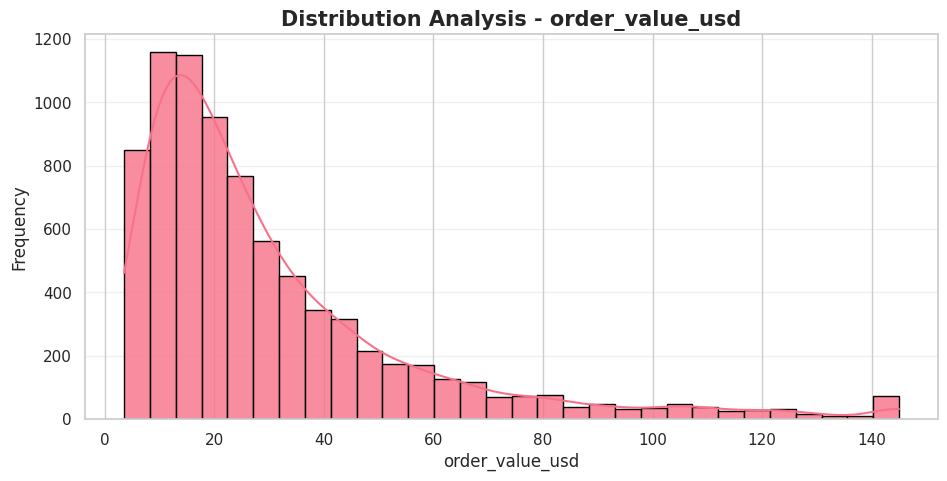

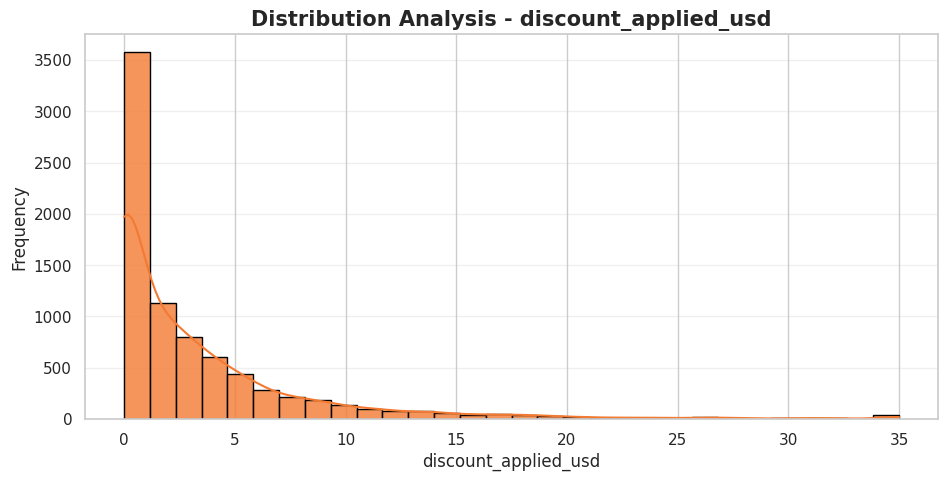

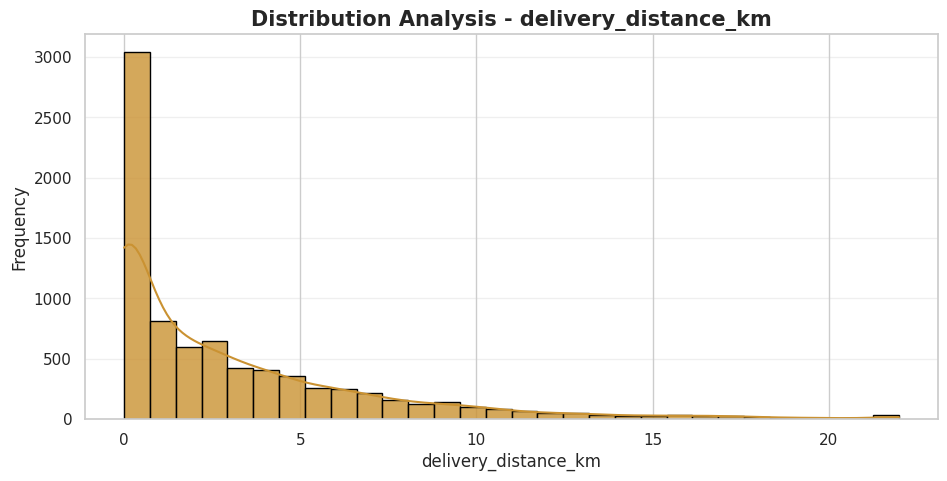

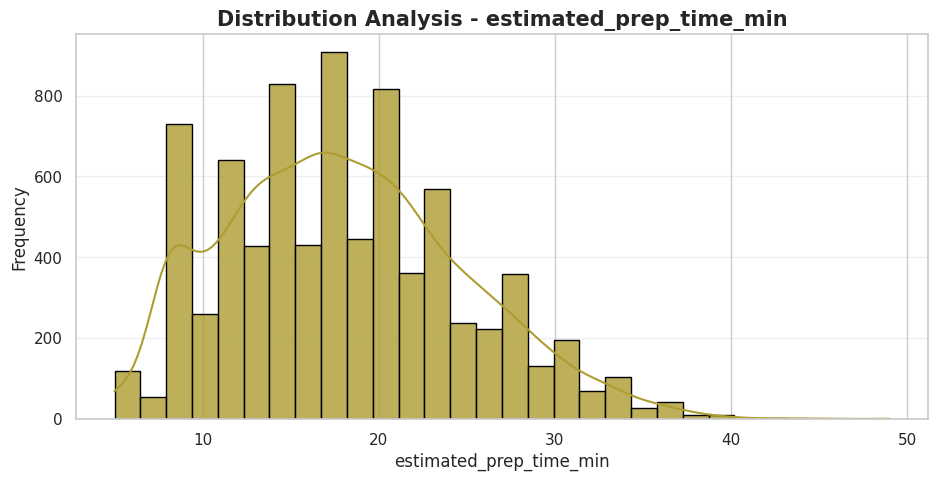

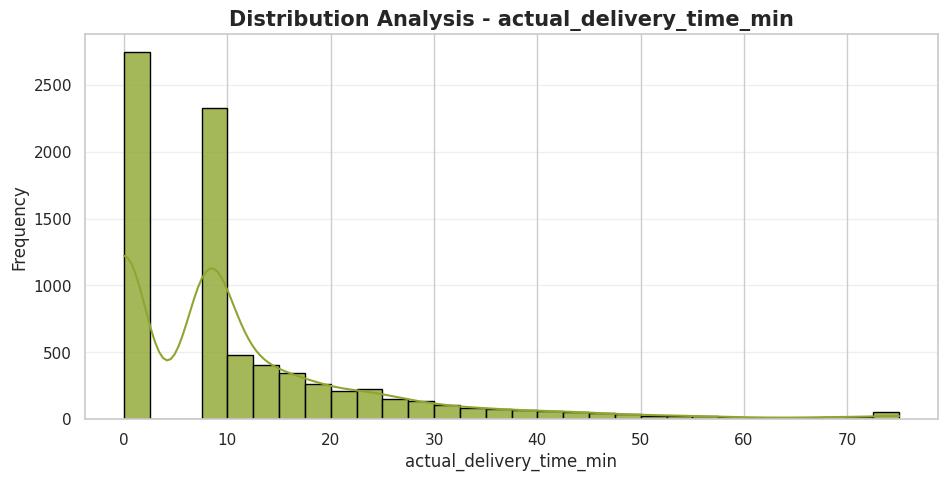

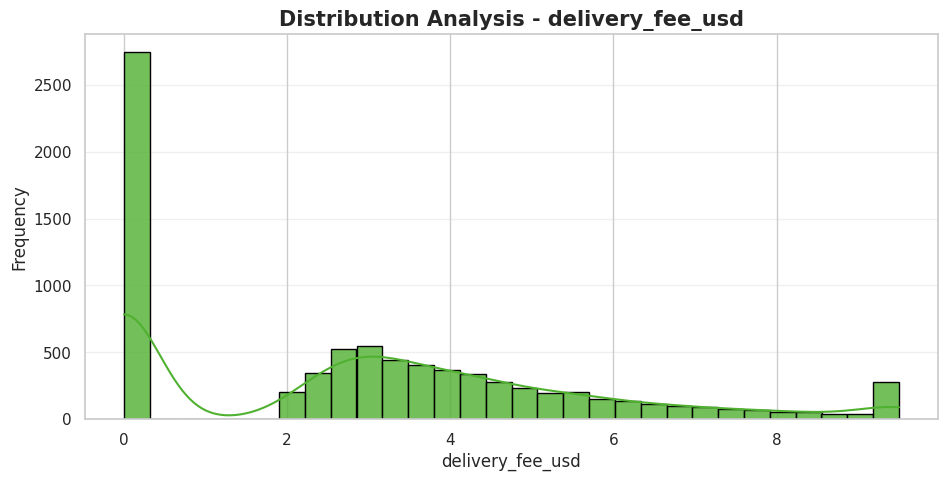

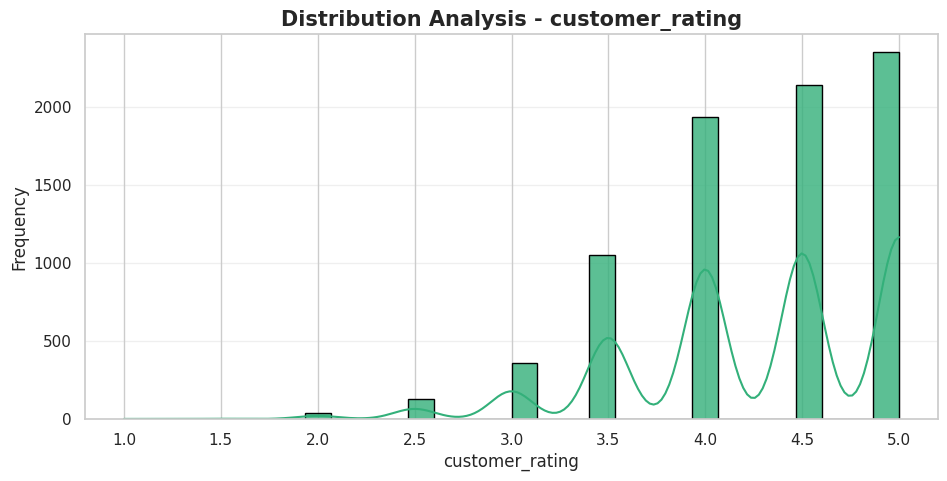

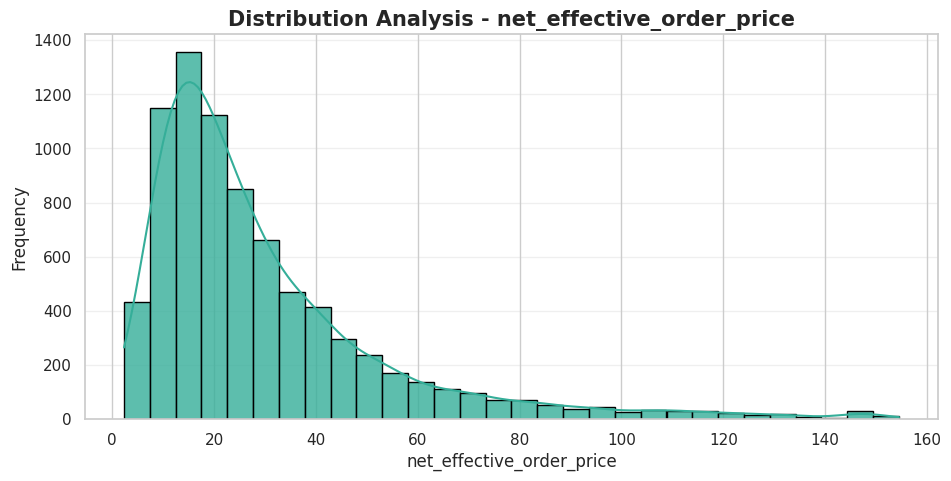

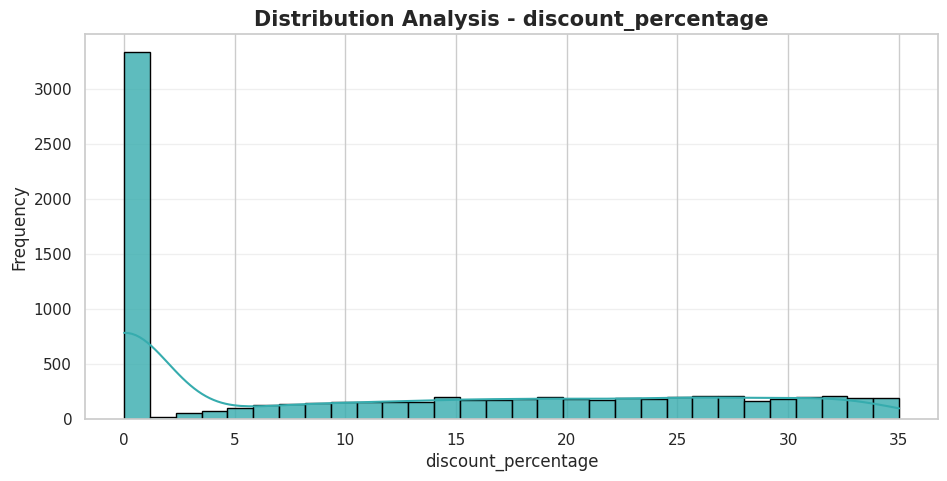

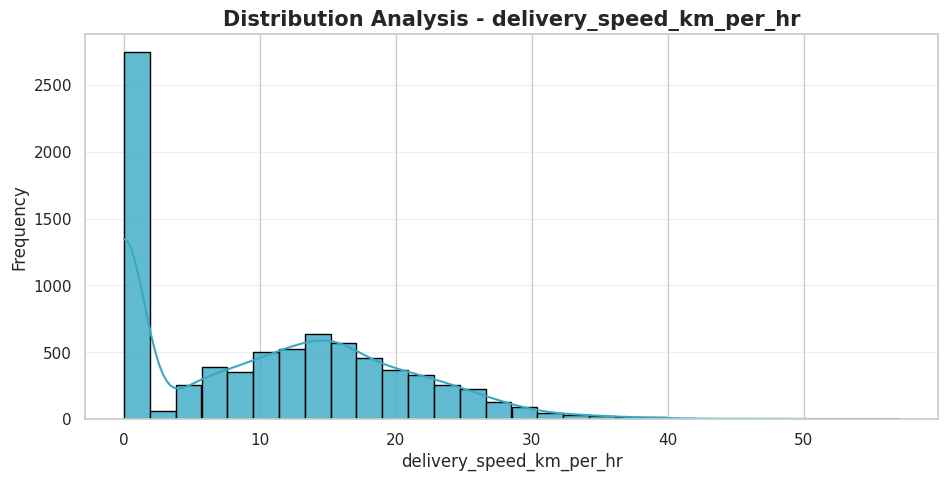

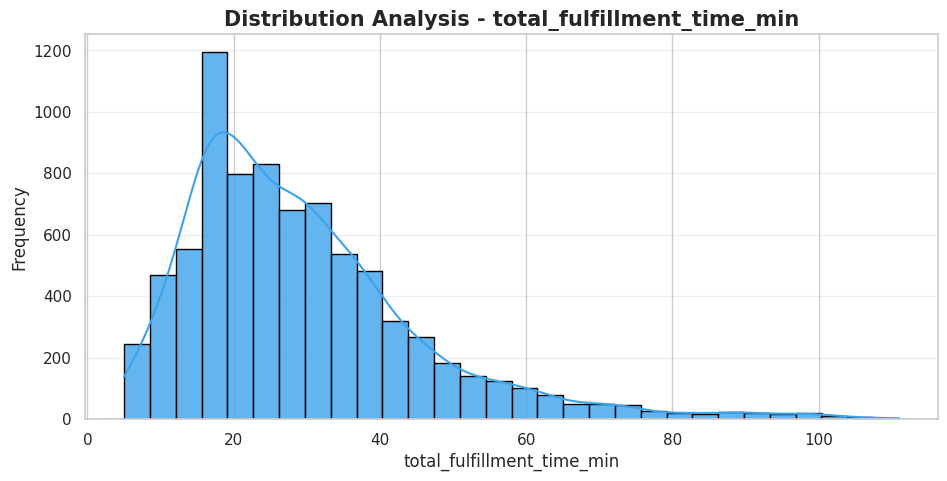

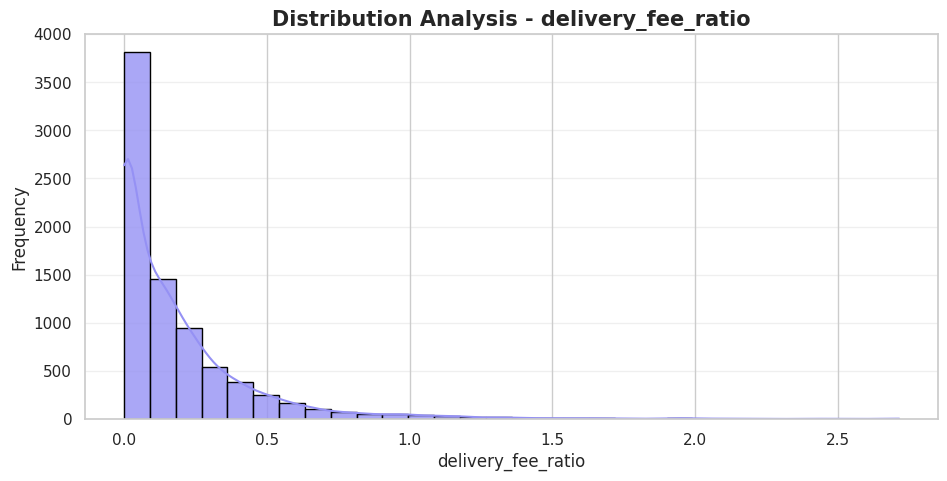

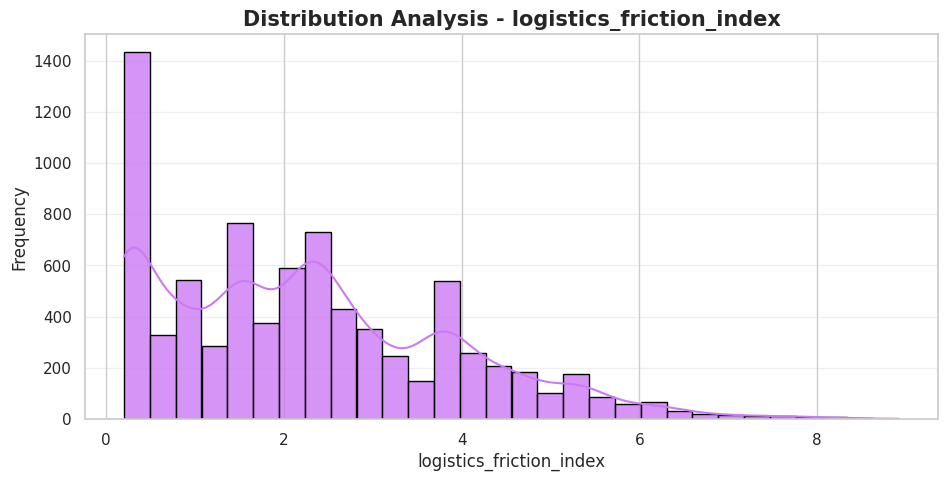

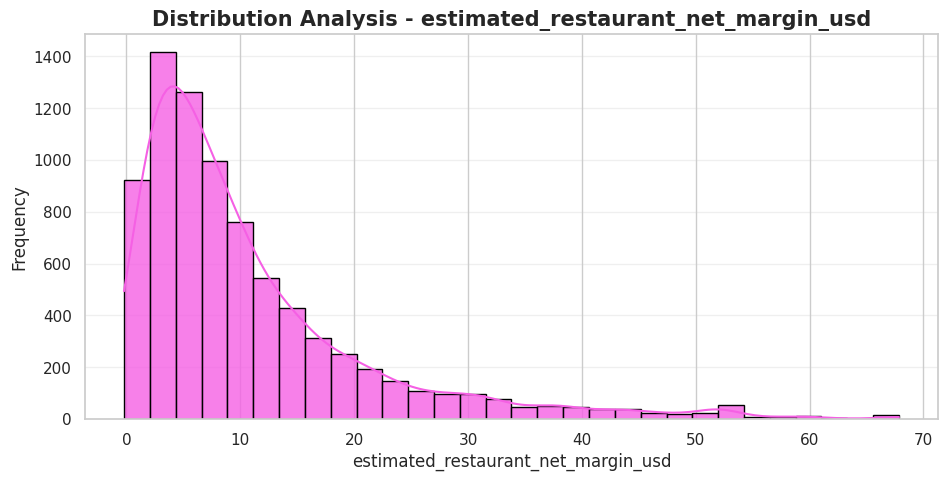

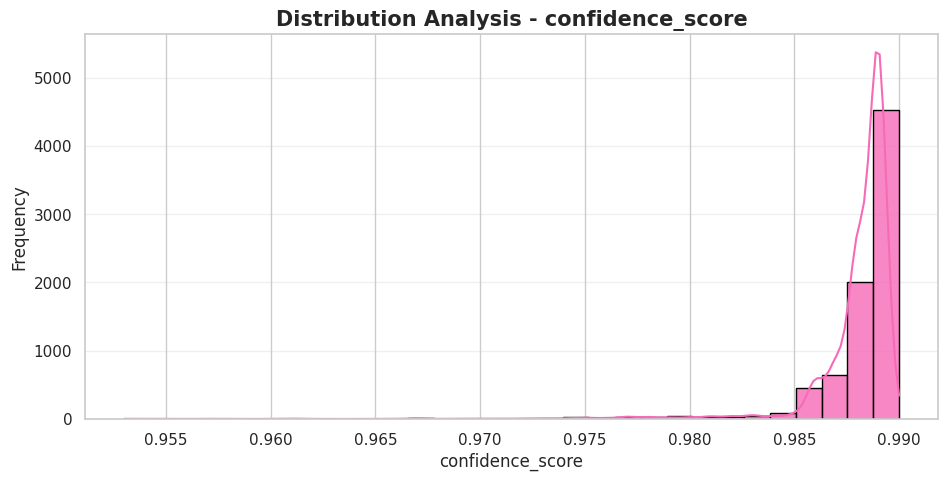

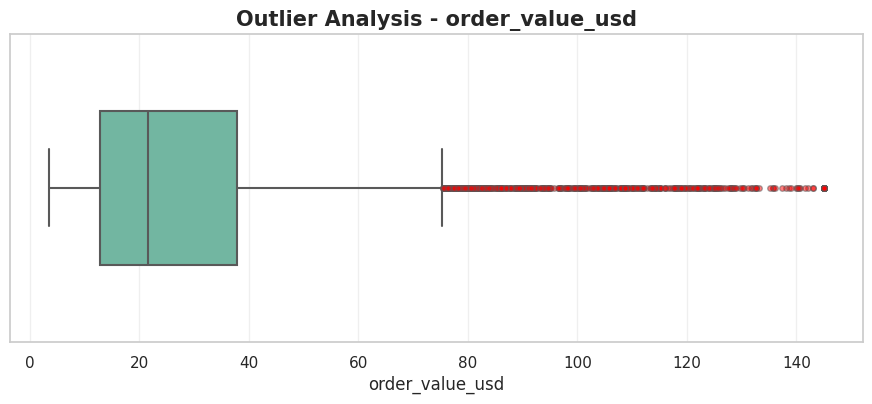

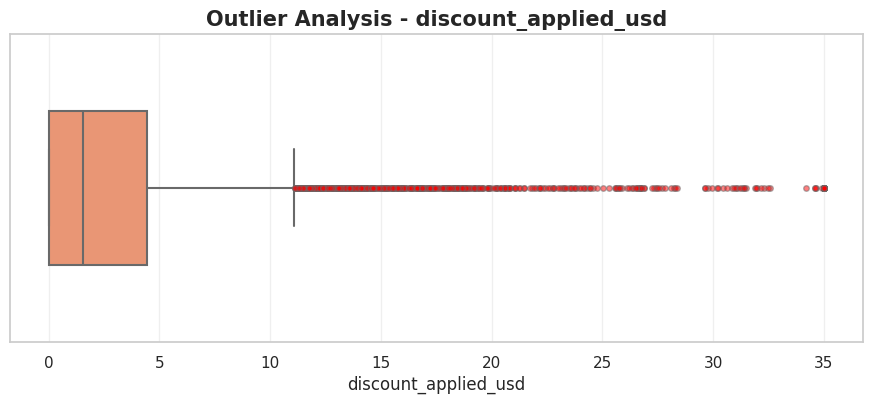

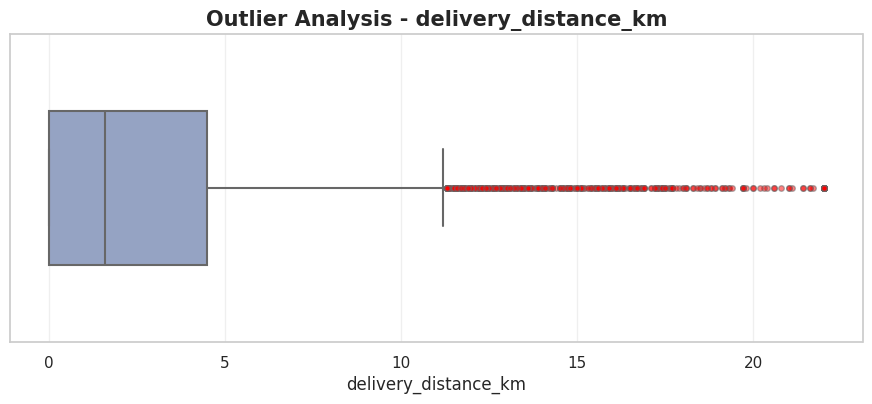

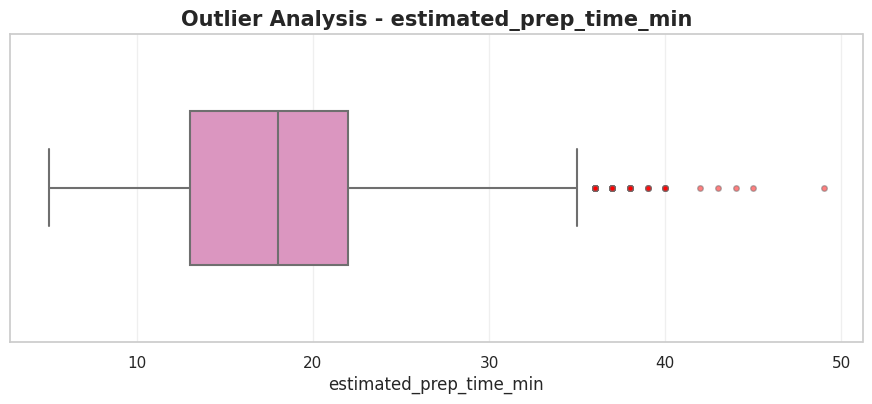

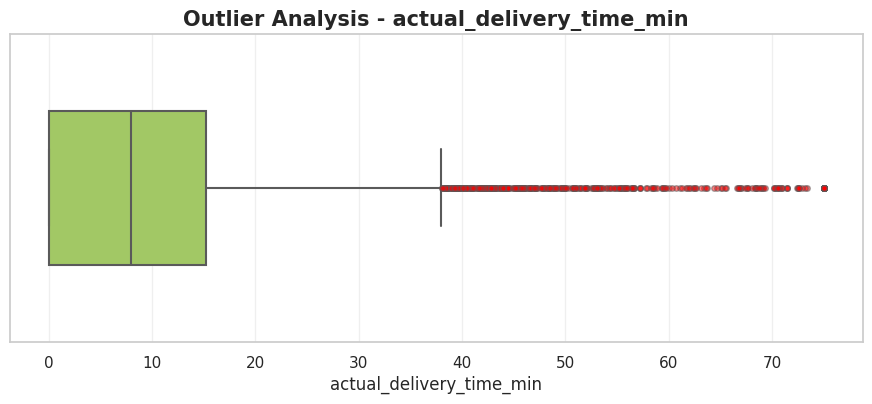

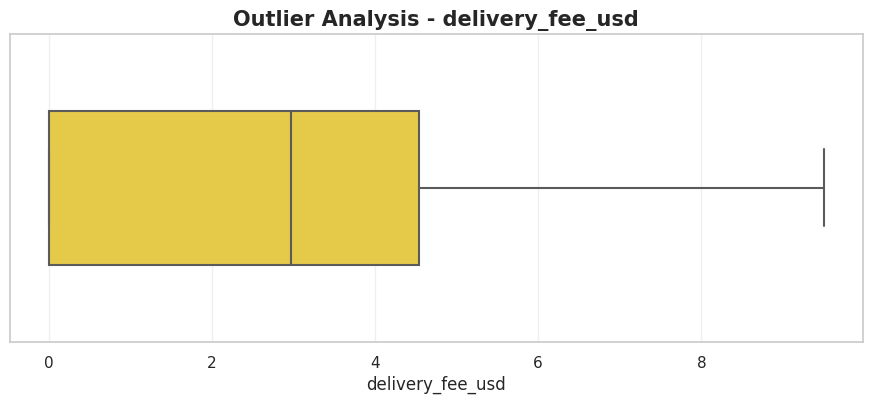

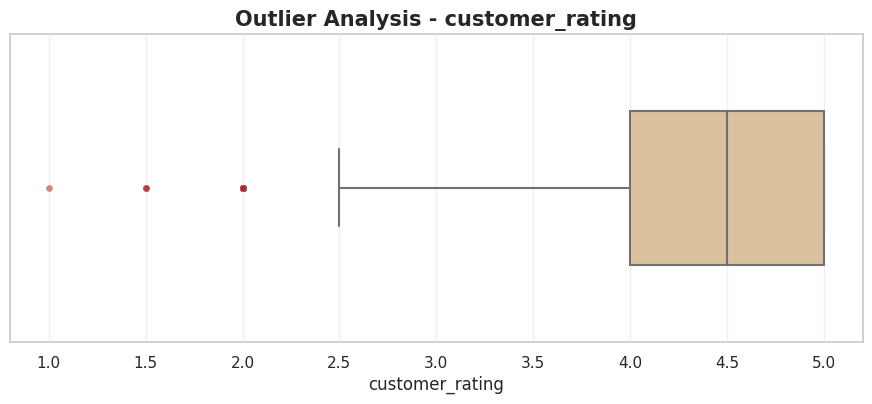

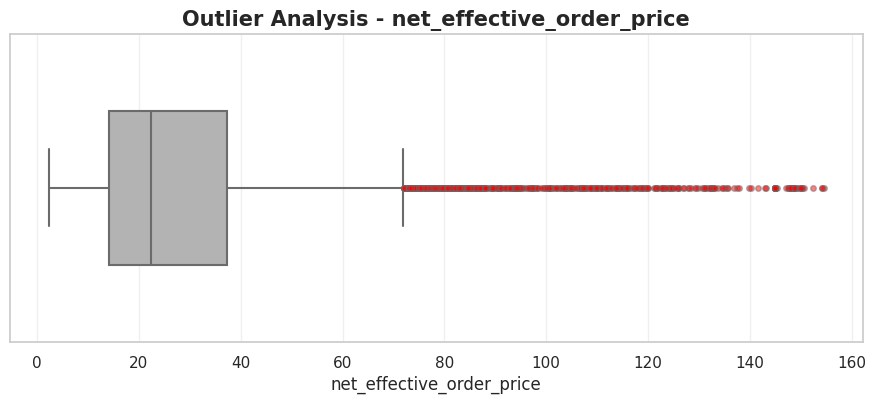

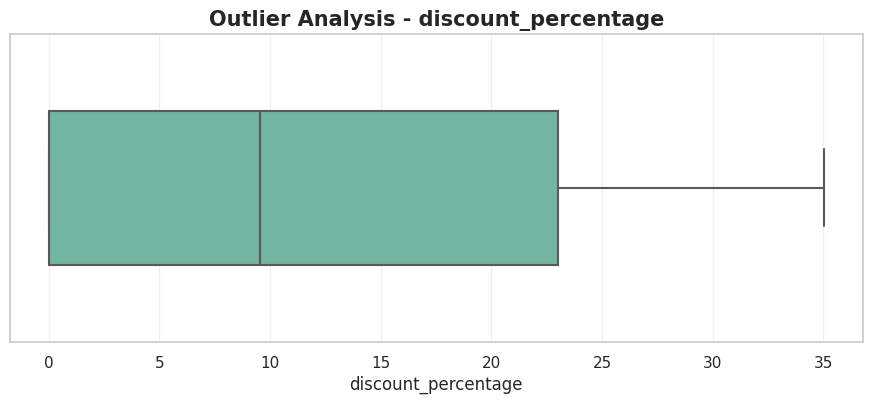

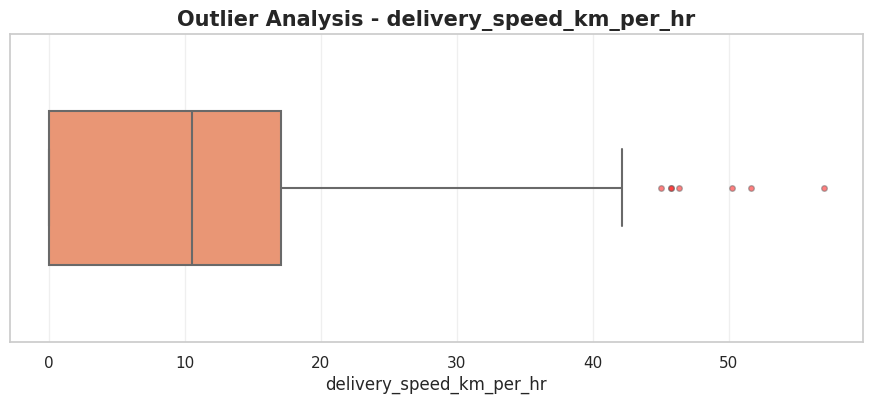

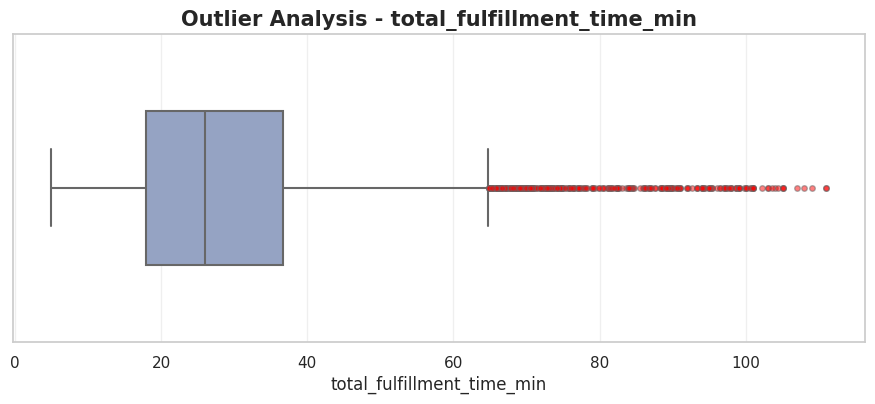

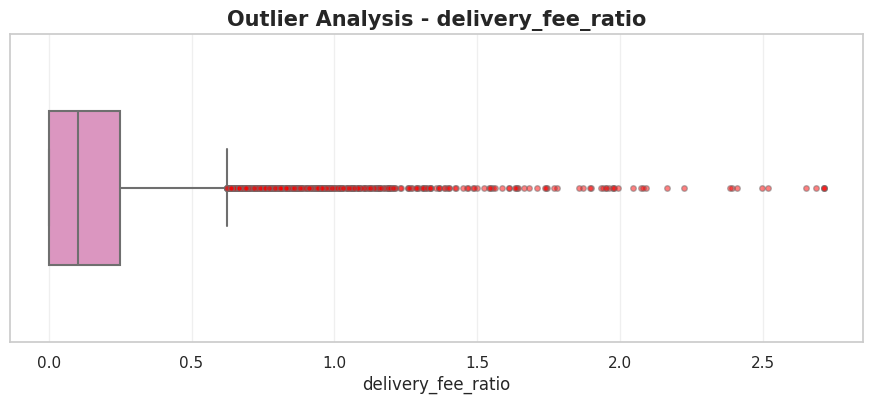

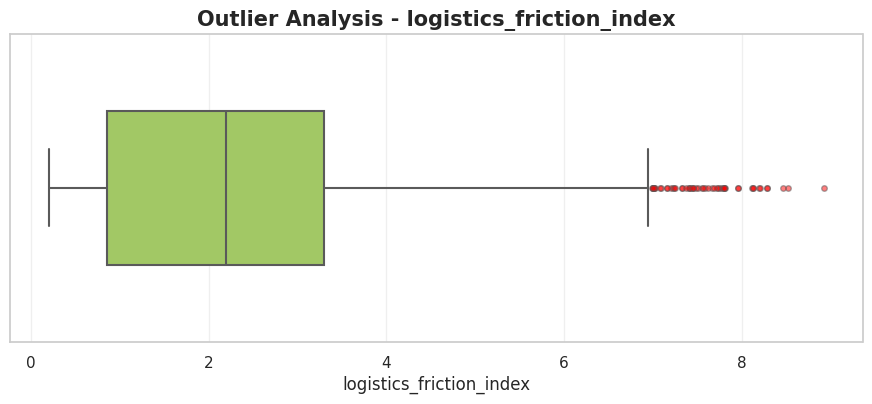

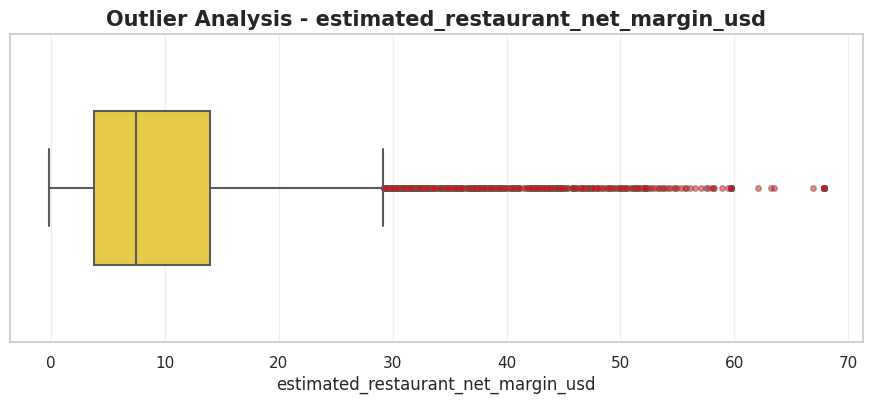

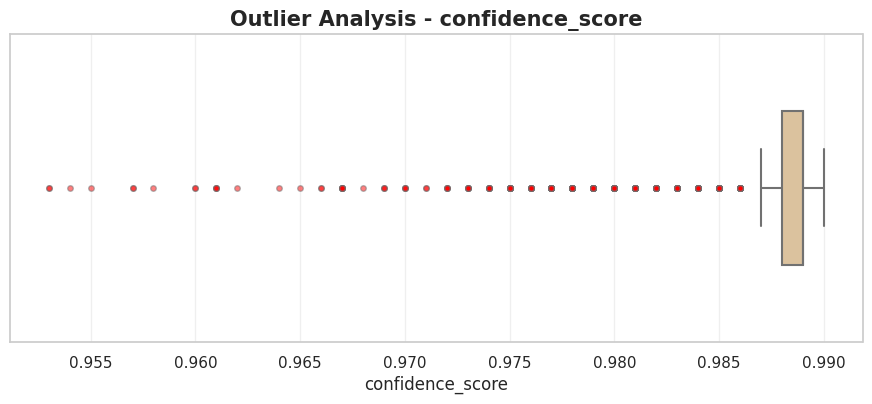

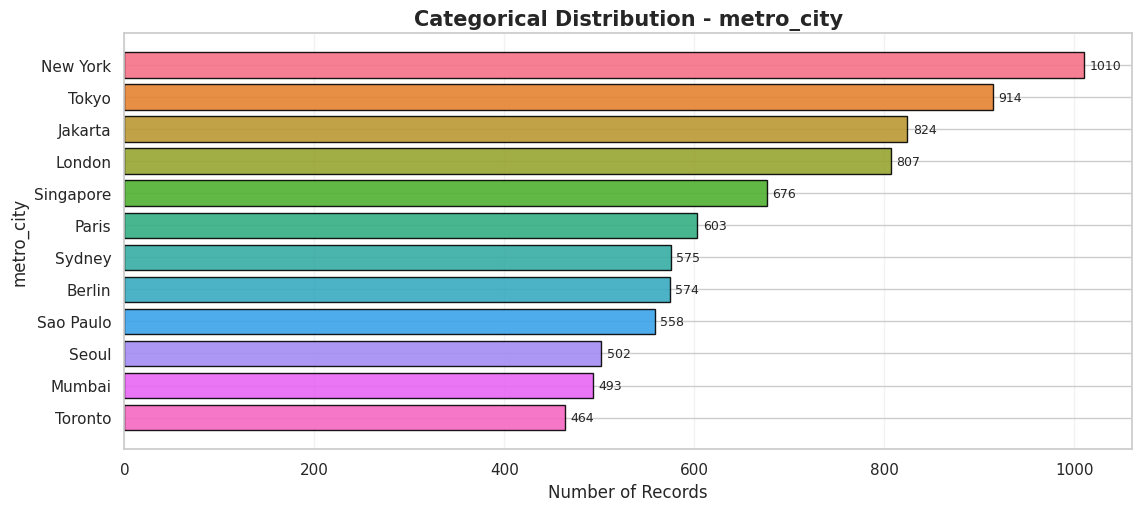

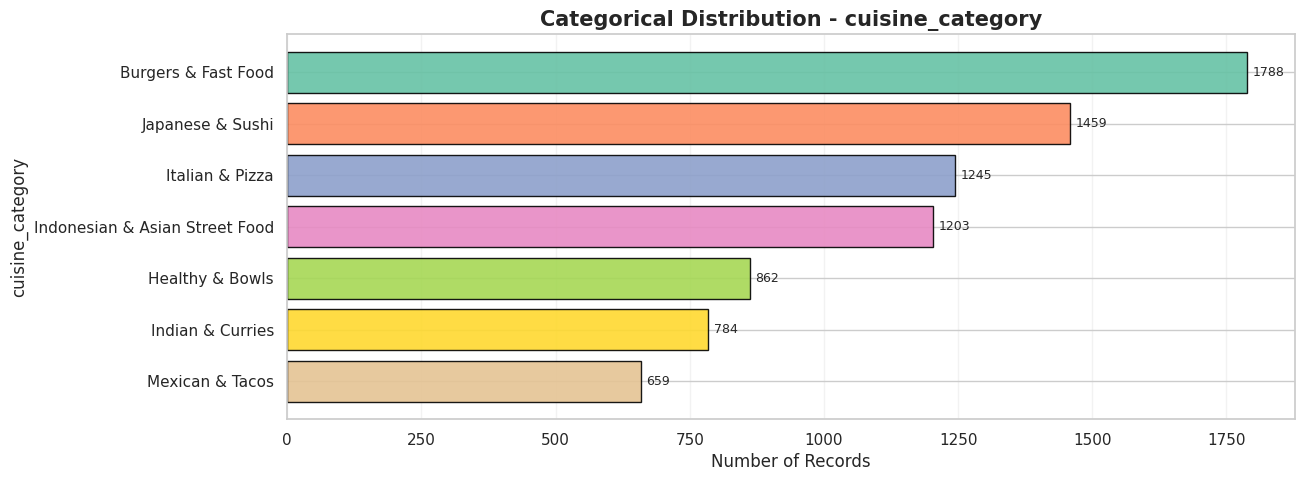

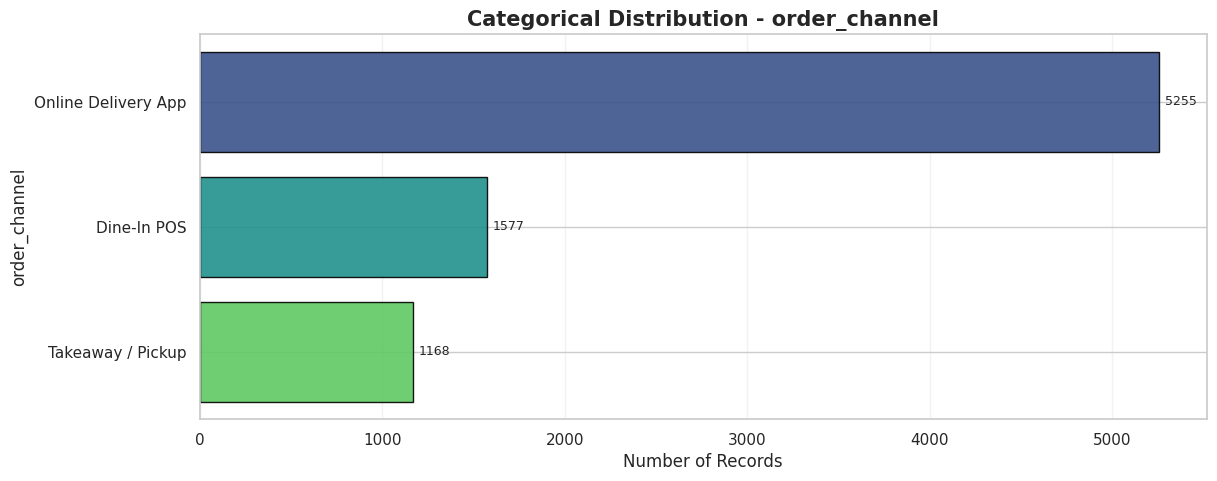

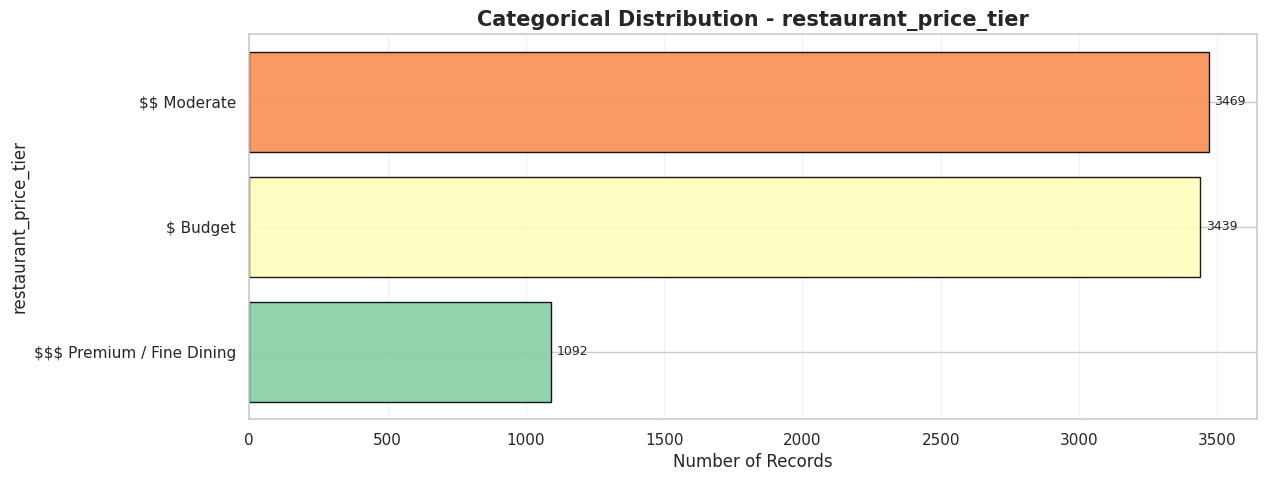

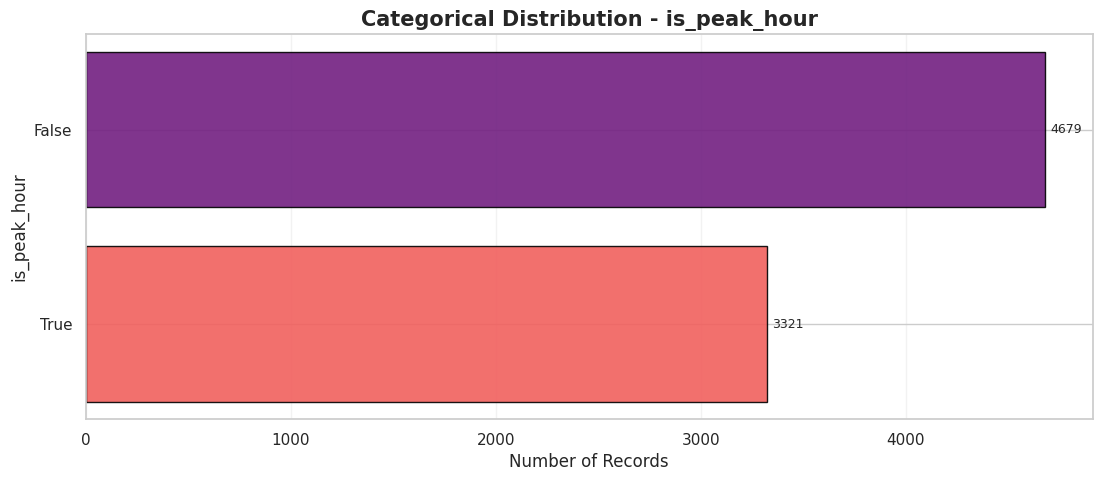

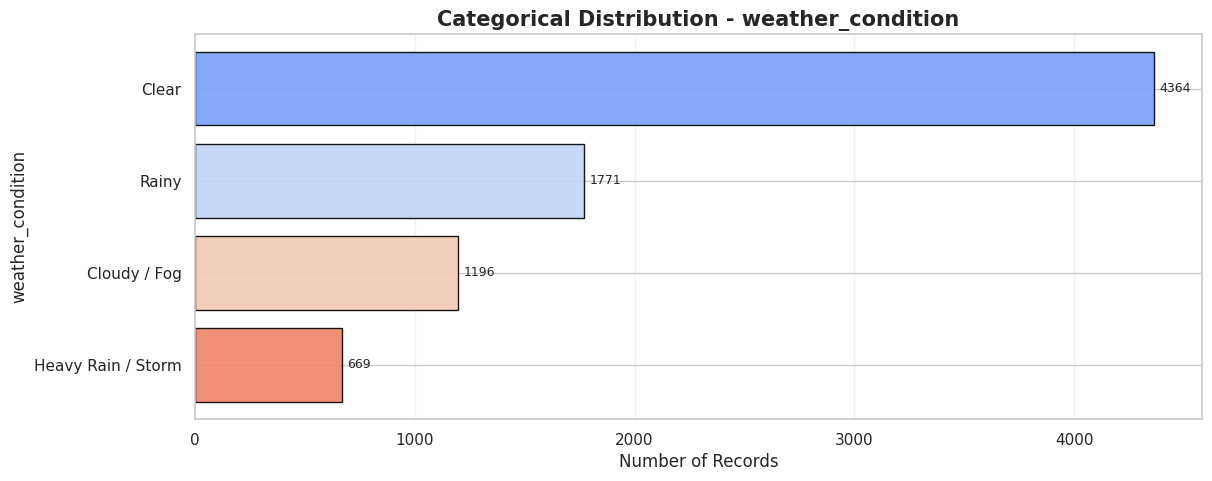

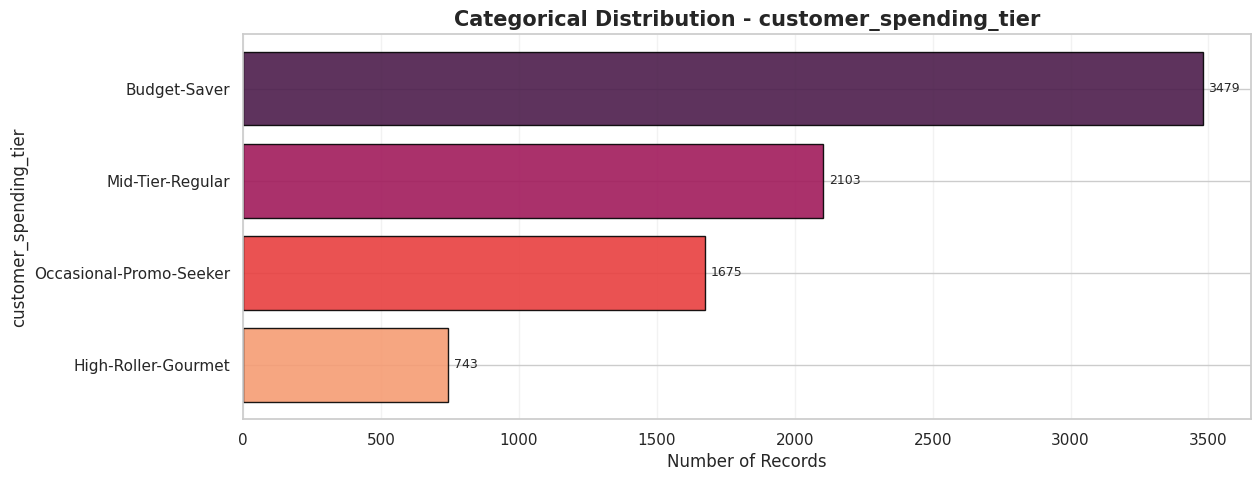

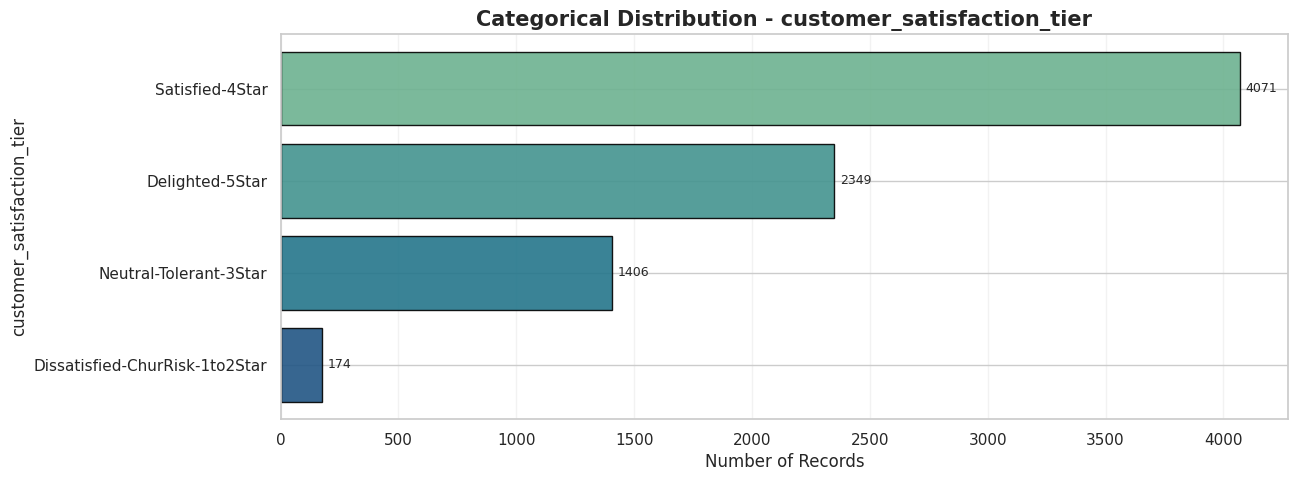

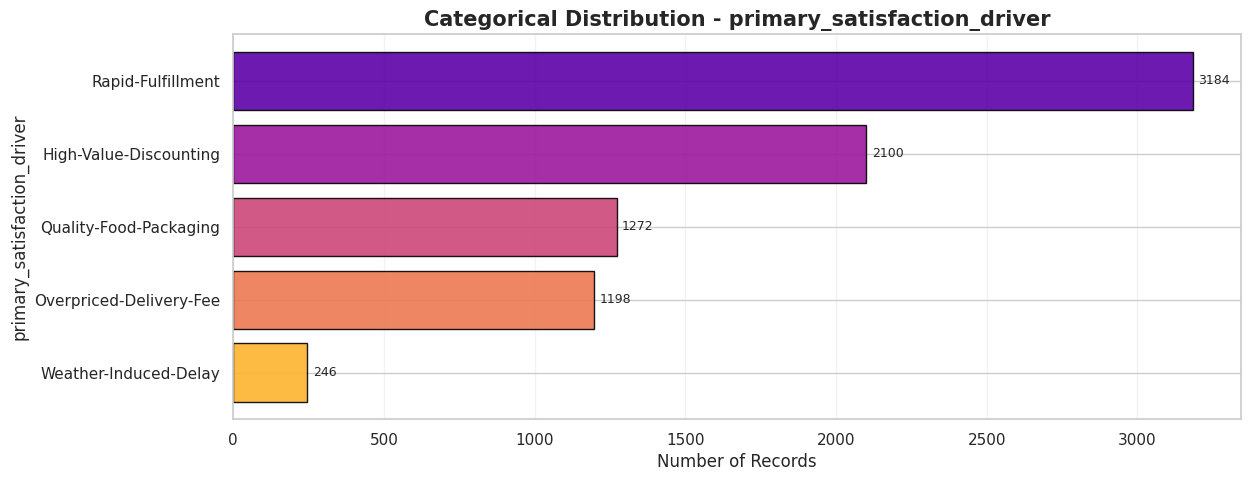

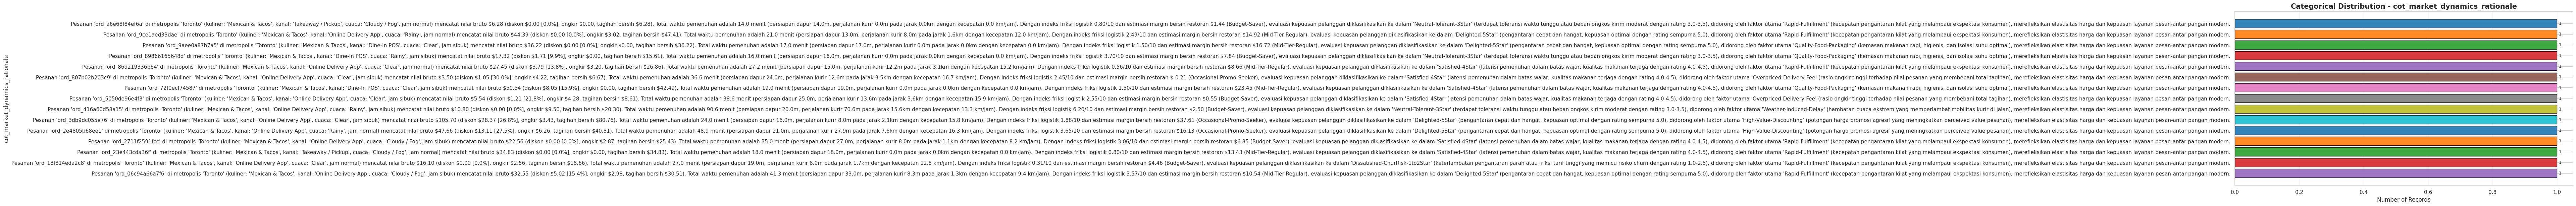

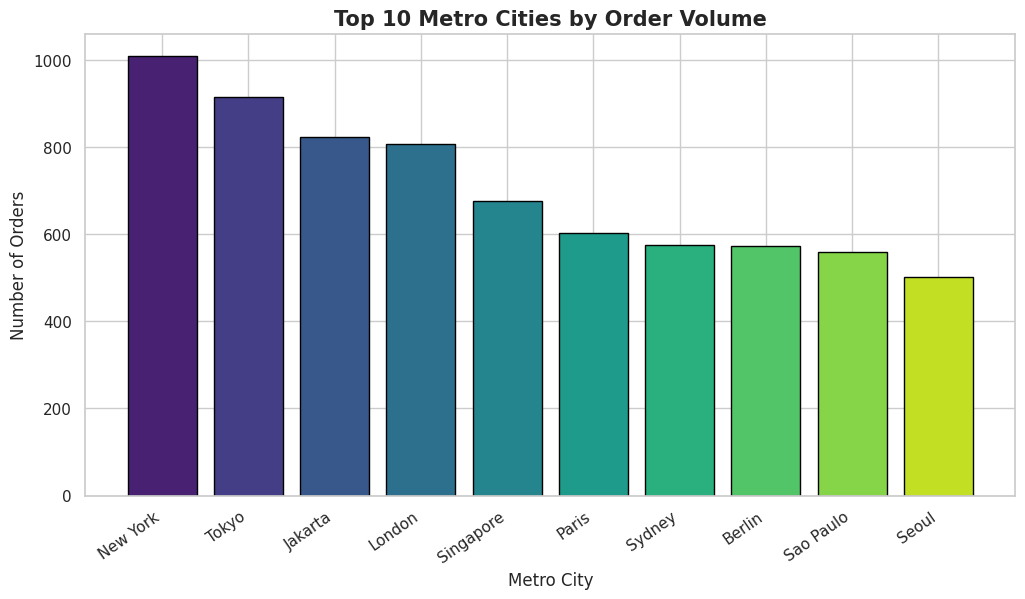

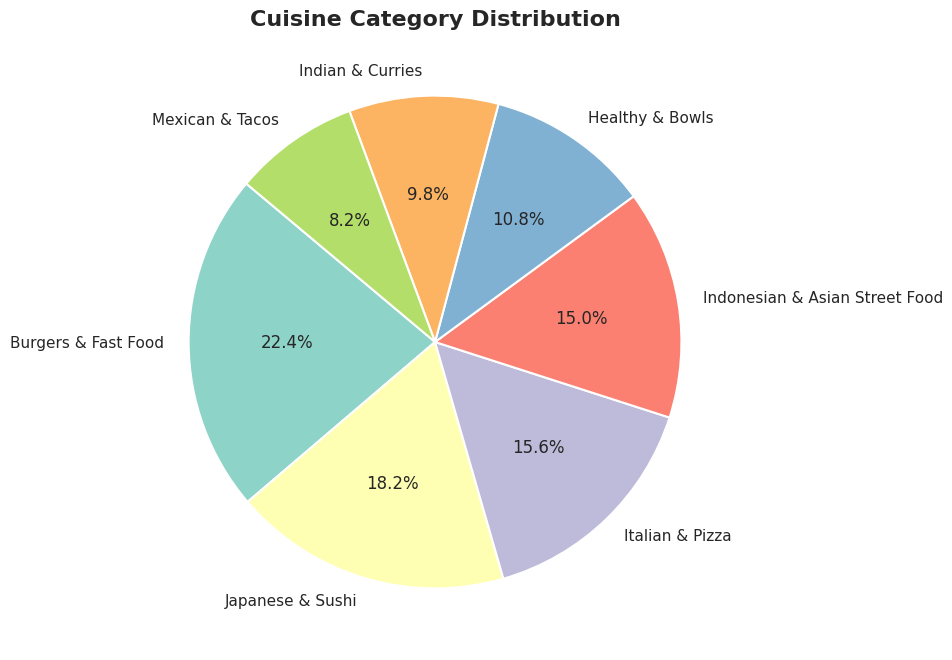

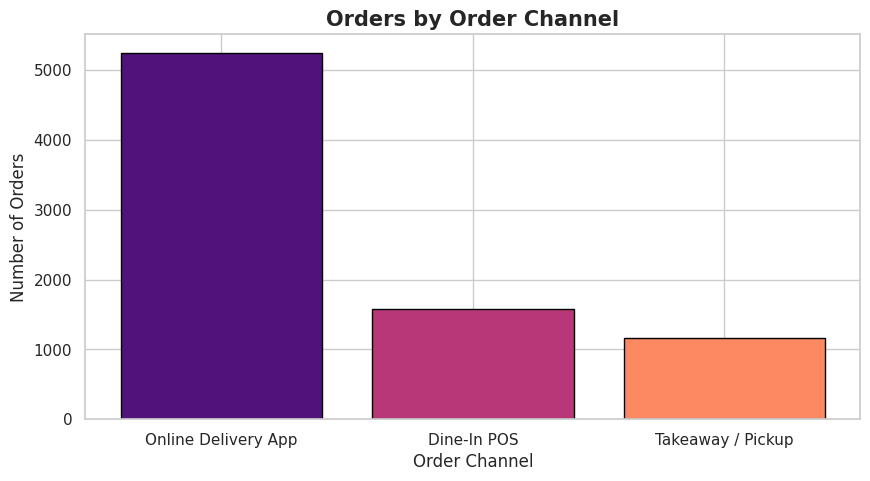

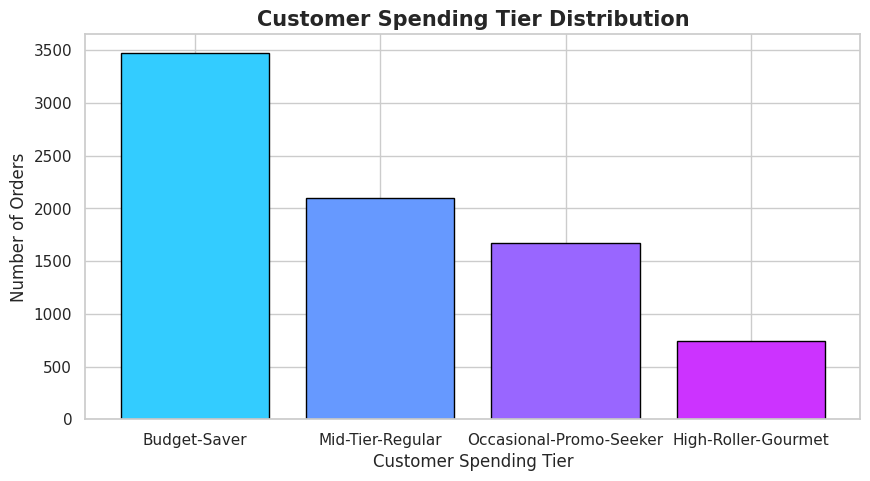

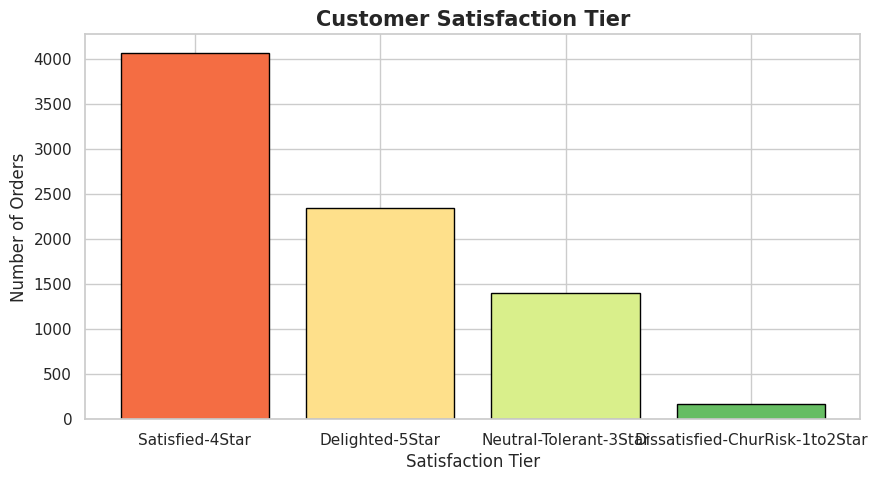

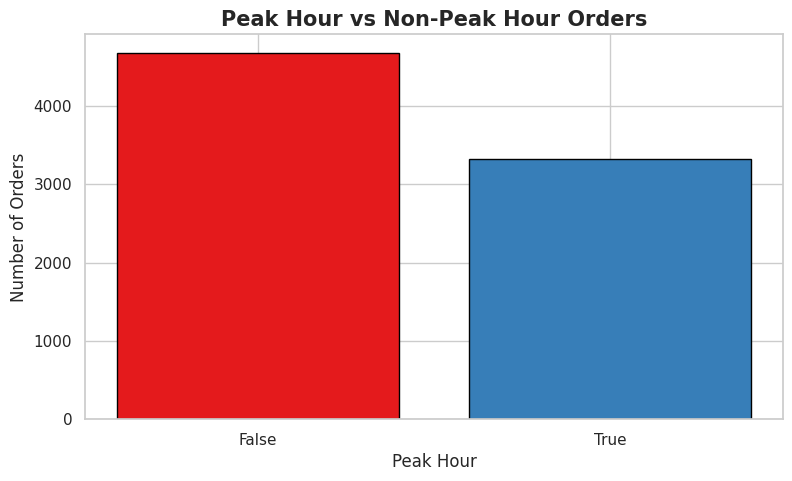

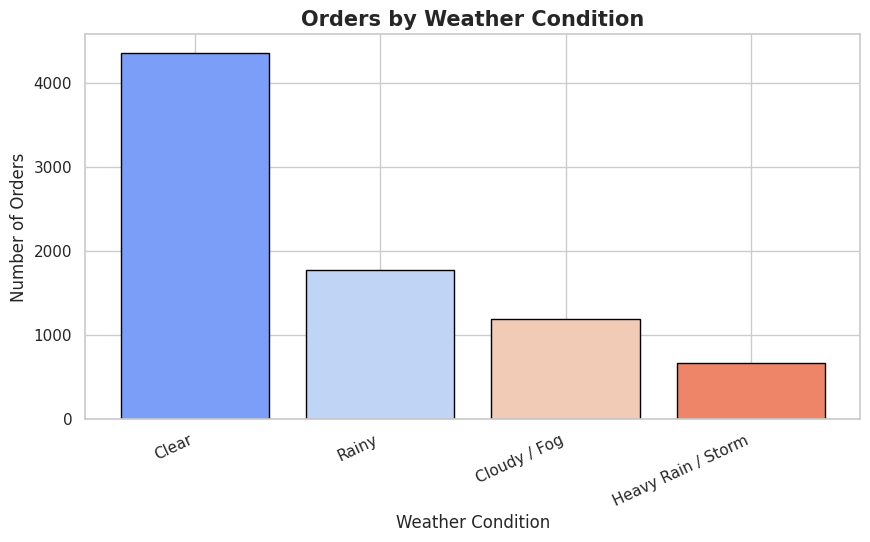

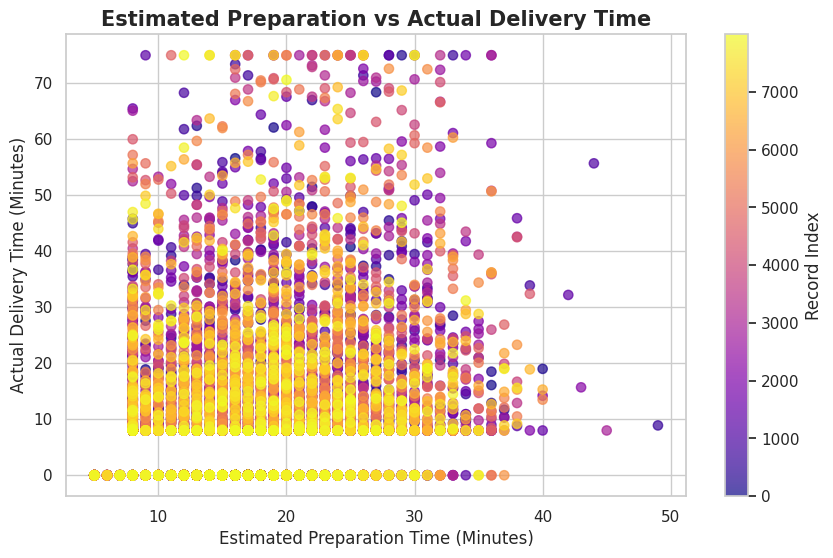

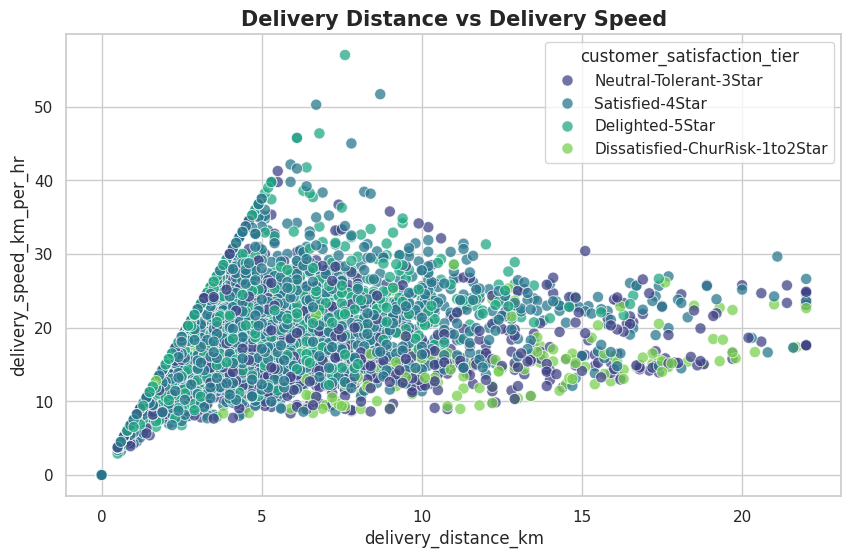

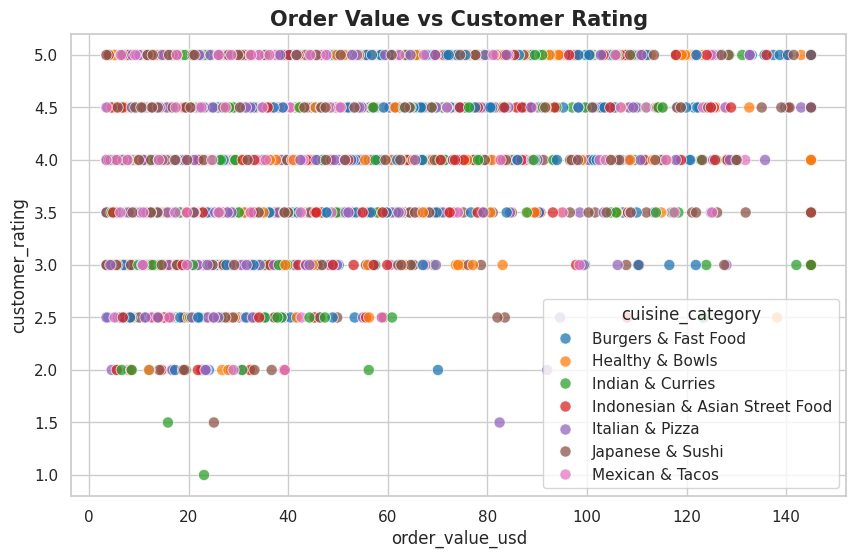

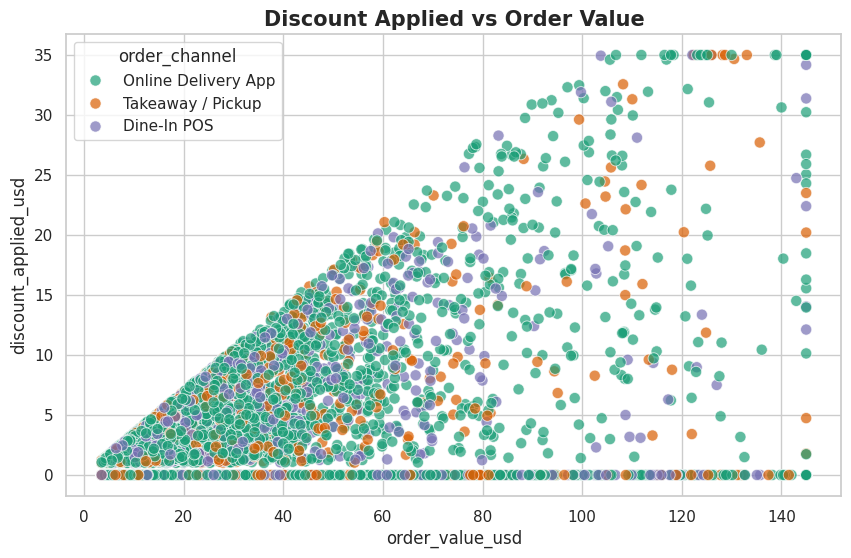

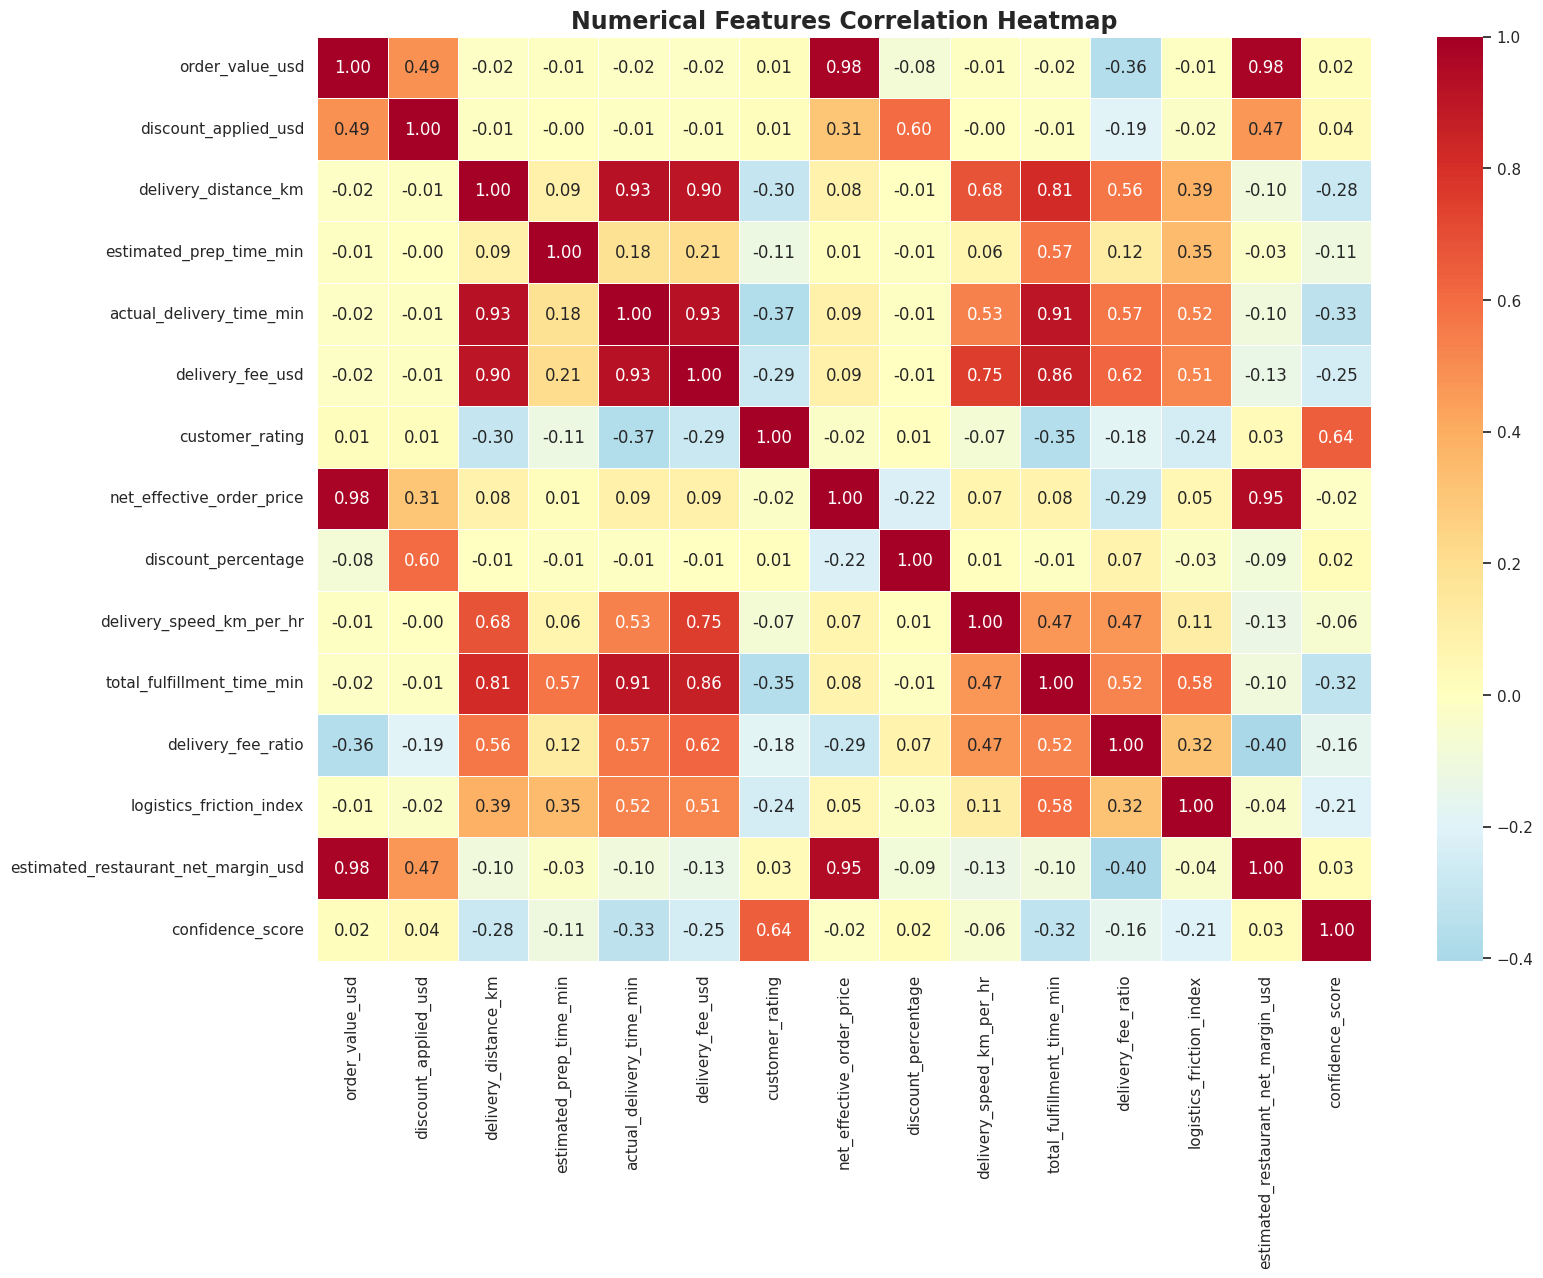

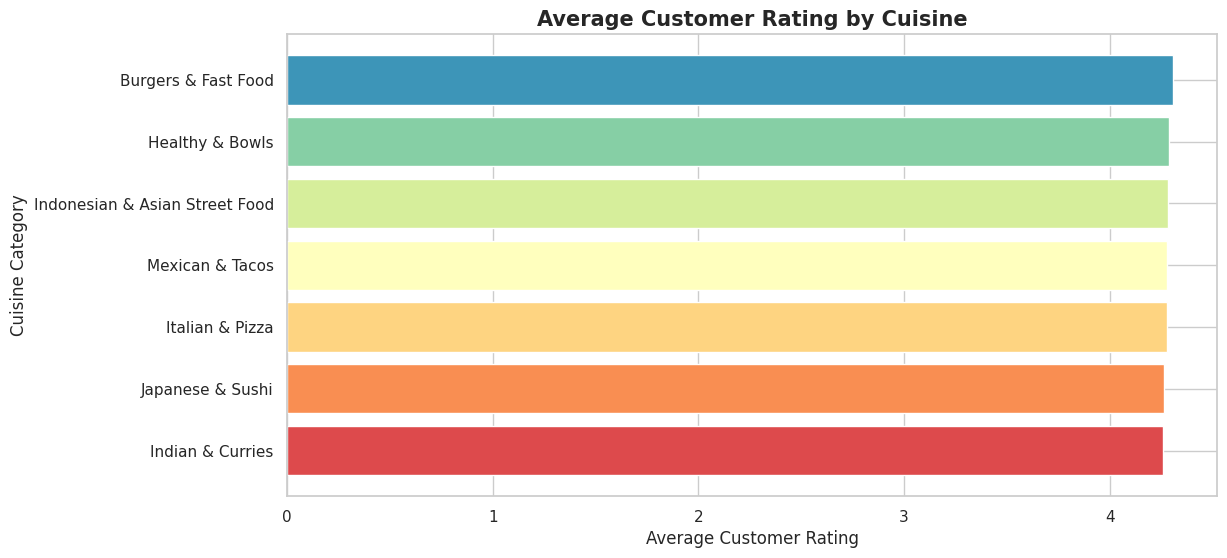

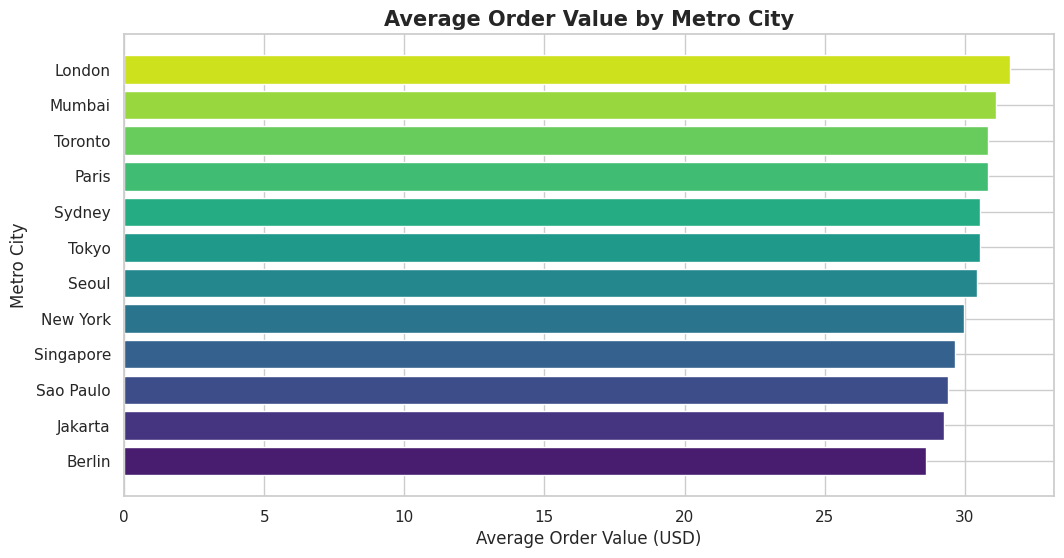

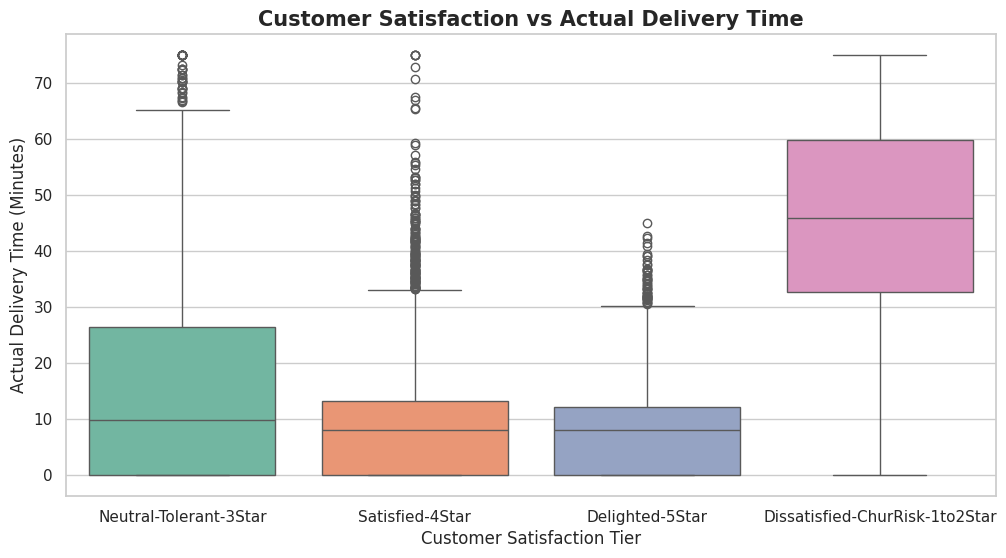

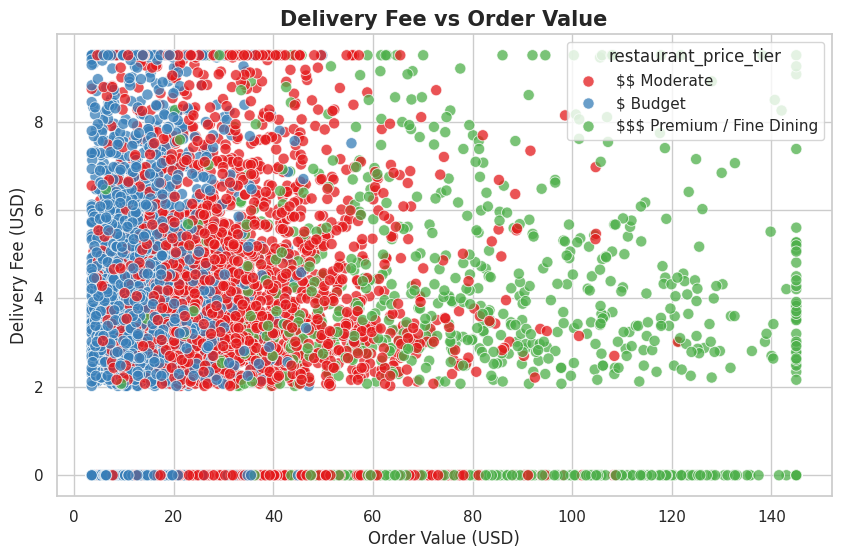

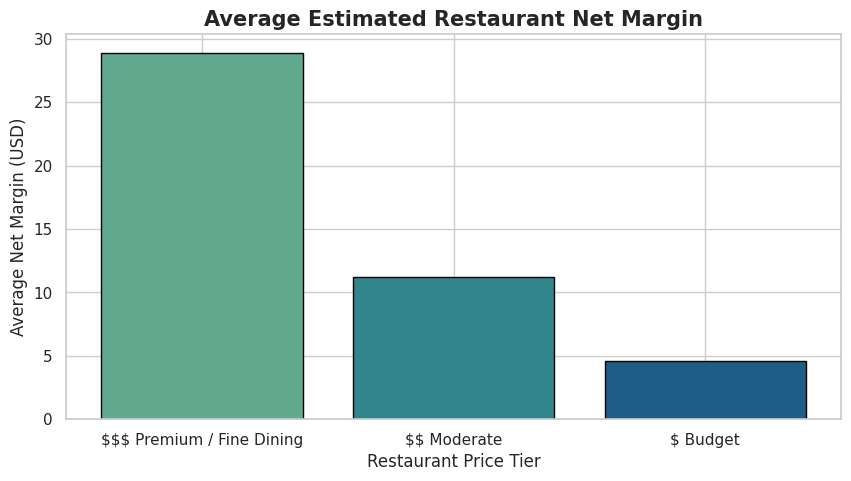

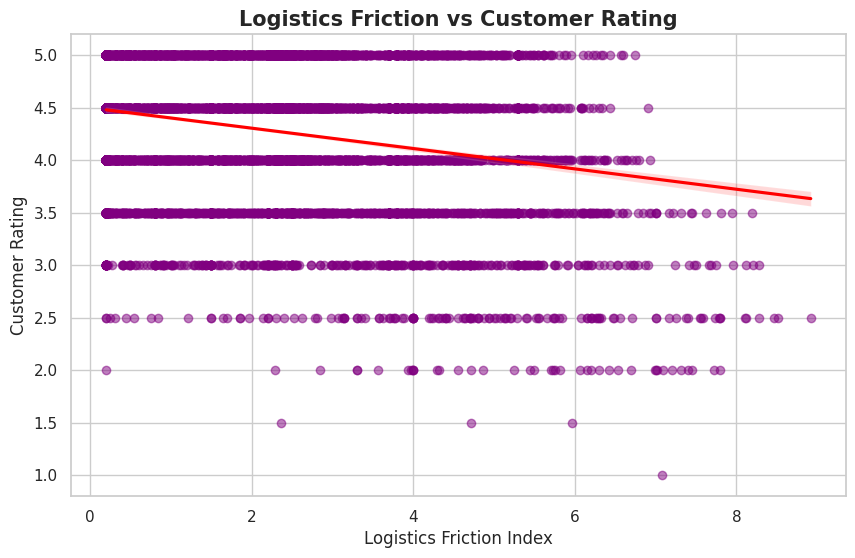

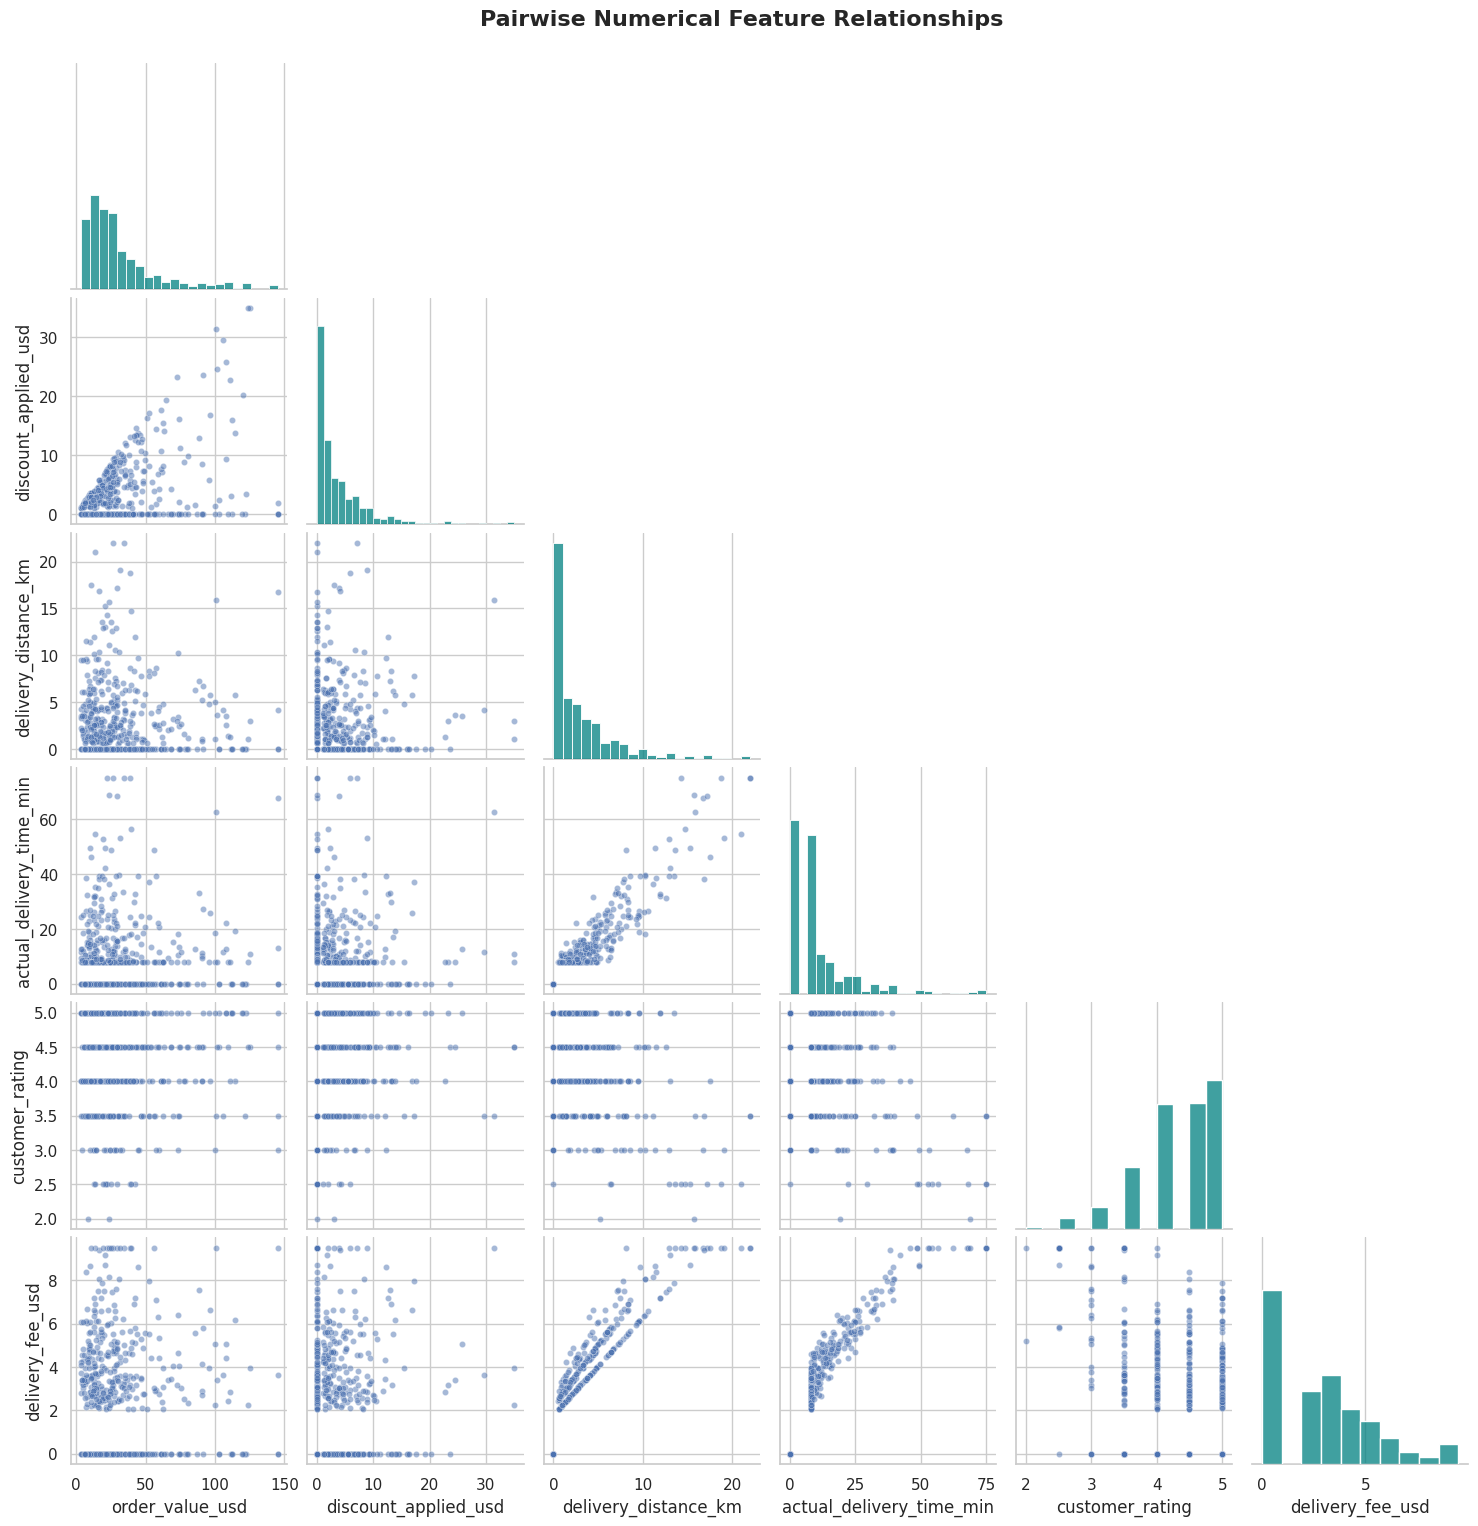


FOOD DELIVERY BUSINESS INSIGHTS

--- Numerical Insights ---
Average Order Value: 30.22 USD
Average Customer Rating: 4.28 
Average Actual Delivery Time: 11.27 minutes
Average Delivery Distance: 3.05 KM
Average Discount: 3.33 USD
Average Delivery Fee: 2.96 USD
Average Restaurant Net Margin: 10.79 USD

--- Categorical Insights ---
Most Frequent Metro City: New York
Most Popular Cuisine: Burgers & Fast Food
Most Used Order Channel: Online Delivery App
Most Common Spending Tier: Budget-Saver
Most Common Satisfaction Tier: Satisfied-4Star
Most Frequent Weather Condition: Clear

FINAL DATASET SUMMARY
Total Records: 8000
Total Features: 26
Numerical Features: 15
Categorical Features: 11
Duplicate Records Remaining: 0
Missing Values Remaining: 0

ALL VISUALIZATION SECTIONS COMPLETED


In [13]:

# =====================================================================
# FOOD DELIVERY DATASET - COMPLETE EDA & DATA VISUALIZATION
# Google Colab / Kaggle - Single Cell Code
# =====================================================================

# 1. IMPORT LIBRARIES
# =====================================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import random

from IPython.display import display

# Disable mathematical parsing of special characters such as $
matplotlib.rcParams["text.parse_math"] = False

# Visualization theme
sns.set_theme(style="whitegrid", context="notebook")

# Different color palettes
PALETTES = [
    "husl", "Set2", "viridis", "Spectral",
    "magma", "coolwarm", "rocket", "crest",
    "plasma", "tab10", "Dark2", "Set3"
]

# =====================================================================
# 2. LOAD / PREPARE DATASET
# =====================================================================

# Make sure your dataset is already loaded into df.
df = df.copy()

print("=" * 75)
print("FOOD DELIVERY DATASET - EXPLORATORY DATA ANALYSIS")
print("=" * 75)

print("\nDataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nFirst Five Records:")
display(df.head())

print("\nLast Five Records:")
display(df.tail())

print("\nStatistical Summary:")
display(df.describe(include="all").T)

print("\nColumn Names:")
print(df.columns.tolist())

# =====================================================================
# 3. DATA CLEANING
# =====================================================================

# Remove duplicate records
duplicate_count = df.duplicated().sum()

print("\nDuplicate Records:", duplicate_count)

df = df.drop_duplicates().copy()

# Missing value analysis
missing_values = df.isnull().sum()

print("\nMissing Values:")
display(missing_values[missing_values > 0])

# Identify numerical and categorical columns
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Exclude identifiers from numerical analysis
numeric_features = [
    col for col in numeric_cols
    if col.lower() not in ["order_id", "id"]
    and df[col].nunique(dropna=True) > 1
]

print("\nNumerical Features:", numeric_features)
print("\nCategorical Features:", categorical_cols)

# =====================================================================
# 4. MISSING VALUE VISUALIZATION
# =====================================================================

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=True)

if not missing.empty:

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.barh(
        missing.index.astype(str),
        missing.values,
        color=sns.color_palette("rocket", len(missing))
    )

    ax.set_title("Missing Values Analysis", fontsize=16, fontweight="bold")
    ax.set_xlabel("Missing Value Count")
    ax.set_ylabel("Features")

    fig.savefig if False else None
    plt.show()
    plt.close(fig)

else:
    print("\nNo missing values detected.")

# =====================================================================
# 5. NUMERICAL DISTRIBUTION ANALYSIS
# =====================================================================

distribution_cols = [
    "order_value_usd",
    "discount_applied_usd",
    "delivery_distance_km",
    "estimated_prep_time_min",
    "actual_delivery_time_min",
    "delivery_fee_usd",
    "customer_rating",
    "net_effective_order_price",
    "discount_percentage",
    "delivery_speed_km_per_hr",
    "total_fulfillment_time_min",
    "delivery_fee_ratio",
    "logistics_friction_index",
    "estimated_restaurant_net_margin_usd",
    "confidence_score"
]

distribution_cols = [
    col for col in distribution_cols
    if col in df.columns
    and pd.api.types.is_numeric_dtype(df[col])
]

for i, col in enumerate(distribution_cols):

    values = pd.to_numeric(df[col], errors="coerce")
    values = values.replace([np.inf, -np.inf], np.nan).dropna()

    if values.empty:
        continue

    fig, ax = plt.subplots(figsize=(11, 5))

    sns.histplot(
        values,
        bins=30,
        kde=len(values) > 2 and values.nunique() > 1,
        color=sns.color_palette("husl", len(distribution_cols))[i],
        edgecolor="black",
        alpha=0.8,
        ax=ax
    )

    ax.set_title(
        f"Distribution Analysis - {col}",
        fontsize=15,
        fontweight="bold"
    )

    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", alpha=0.3)

    plt.show()
    plt.close(fig)

# =====================================================================
# 6. BOXPLOT - OUTLIER ANALYSIS
# =====================================================================

box_colors = sns.color_palette("Set2", max(len(numeric_features), 1))

for i, col in enumerate(numeric_features):

    values = pd.to_numeric(df[col], errors="coerce")
    values = values.replace([np.inf, -np.inf], np.nan).dropna()

    if values.empty:
        continue

    fig, ax = plt.subplots(figsize=(11, 4))

    sns.boxplot(
        x=values,
        color=box_colors[i % len(box_colors)],
        width=0.5,
        linewidth=1.5,
        ax=ax,
        flierprops={
            "marker": "o",
            "markerfacecolor": "red",
            "markersize": 4,
            "alpha": 0.5
        }
    )

    ax.set_title(
        f"Outlier Analysis - {col}",
        fontsize=15,
        fontweight="bold"
    )

    ax.set_xlabel(col)
    ax.grid(axis="x", alpha=0.3)

    plt.show()
    plt.close(fig)

# =====================================================================
# 7. CATEGORICAL FEATURE ANALYSIS
# =====================================================================

categorical_visual_cols = [
    "metro_city",
    "cuisine_category",
    "order_channel",
    "restaurant_price_tier",
    "is_peak_hour",
    "weather_condition",
    "customer_spending_tier",
    "customer_satisfaction_tier",
    "primary_satisfaction_driver",
    "cot_market_dynamics_rationale"
]

categorical_visual_cols = [
    col for col in categorical_visual_cols
    if col in df.columns
]

for i, col in enumerate(categorical_visual_cols):

    values = df[col].dropna().astype(str)

    if values.empty:
        continue

    # Display top 15 categories to avoid overcrowding
    counts = values.value_counts().head(15)

    fig_height = max(5, len(counts) * 0.45)

    fig, ax = plt.subplots(figsize=(13, fig_height))

    palette = sns.color_palette(
        PALETTES[i % len(PALETTES)],
        n_colors=len(counts)
    )

    ax.barh(
        counts.index[::-1],
        counts.values[::-1],
        color=palette[::-1],
        edgecolor="black",
        alpha=0.9
    )

    for container in ax.containers:
        ax.bar_label(container, padding=4, fontsize=9)

    ax.set_title(
        f"Categorical Distribution - {col}",
        fontsize=15,
        fontweight="bold"
    )

    ax.set_xlabel("Number of Records")
    ax.set_ylabel(col)
    ax.grid(axis="x", alpha=0.25)

    plt.show()
    plt.close(fig)

# =====================================================================
# 8. TOP 10 METRO CITIES
# =====================================================================

if "metro_city" in df.columns:

    city_orders = df["metro_city"].dropna().value_counts().head(10)

    if not city_orders.empty:

        fig, ax = plt.subplots(figsize=(12, 6))

        ax.bar(
            city_orders.index.astype(str),
            city_orders.values,
            color=sns.color_palette("viridis", len(city_orders)),
            edgecolor="black"
        )

        ax.set_title("Top 10 Metro Cities by Order Volume",
                     fontsize=15, fontweight="bold")
        ax.set_xlabel("Metro City")
        ax.set_ylabel("Number of Orders")
        plt.setp(ax.get_xticklabels(), rotation=35, ha="right")

        plt.show()
        plt.close(fig)

# =====================================================================
# 9. CUISINE CATEGORY DISTRIBUTION
# =====================================================================

if "cuisine_category" in df.columns:

    cuisine = df["cuisine_category"].dropna().astype(str).value_counts()

    if not cuisine.empty:

        # Combine smaller categories into Other
        top_cuisine = cuisine.head(9).copy()

        if len(cuisine) > 9:
            top_cuisine.loc["Other"] = cuisine.iloc[9:].sum()

        fig, ax = plt.subplots(figsize=(9, 8))

        ax.pie(
            top_cuisine.values,
            labels=top_cuisine.index,
            autopct="%1.1f%%",
            startangle=140,
            colors=sns.color_palette("Set3", len(top_cuisine)),
            wedgeprops={"edgecolor": "white", "linewidth": 1.5}
        )

        ax.set_title("Cuisine Category Distribution",
                     fontsize=16, fontweight="bold")

        plt.show()
        plt.close(fig)

# =====================================================================
# 10. ORDER CHANNEL ANALYSIS
# =====================================================================

if "order_channel" in df.columns:

    channel = df["order_channel"].dropna().astype(str).value_counts()

    if not channel.empty:

        fig, ax = plt.subplots(figsize=(10, 5))

        ax.bar(
            channel.index,
            channel.values,
            color=sns.color_palette("magma", len(channel)),
            edgecolor="black"
        )

        ax.set_title("Orders by Order Channel",
                     fontsize=15, fontweight="bold")
        ax.set_xlabel("Order Channel")
        ax.set_ylabel("Number of Orders")

        plt.show()
        plt.close(fig)

# =====================================================================
# 11. CUSTOMER SPENDING TIER
# =====================================================================

if "customer_spending_tier" in df.columns:

    spending = df["customer_spending_tier"].dropna().astype(str).value_counts()

    if not spending.empty:

        fig, ax = plt.subplots(figsize=(10, 5))

        ax.bar(
            spending.index,
            spending.values,
            color=sns.color_palette("cool", len(spending)),
            edgecolor="black"
        )

        ax.set_title("Customer Spending Tier Distribution",
                     fontsize=15, fontweight="bold")
        ax.set_xlabel("Customer Spending Tier")
        ax.set_ylabel("Number of Orders")

        plt.show()
        plt.close(fig)

# =====================================================================
# 12. CUSTOMER SATISFACTION TIER
# =====================================================================

if "customer_satisfaction_tier" in df.columns:

    satisfaction = (
        df["customer_satisfaction_tier"]
        .dropna()
        .astype(str)
        .value_counts()
    )

    if not satisfaction.empty:

        fig, ax = plt.subplots(figsize=(10, 5))

        ax.bar(
            satisfaction.index,
            satisfaction.values,
            color=sns.color_palette("RdYlGn", len(satisfaction)),
            edgecolor="black"
        )

        ax.set_title("Customer Satisfaction Tier",
                     fontsize=15, fontweight="bold")
        ax.set_xlabel("Satisfaction Tier")
        ax.set_ylabel("Number of Orders")

        plt.show()
        plt.close(fig)

# =====================================================================
# 13. PEAK HOUR VS NON-PEAK HOUR
# =====================================================================

if "is_peak_hour" in df.columns:

    peak = df["is_peak_hour"].dropna().astype(str).value_counts()

    if not peak.empty:

        fig, ax = plt.subplots(figsize=(9, 5))

        ax.bar(
            peak.index,
            peak.values,
            color=sns.color_palette("Set1", len(peak)),
            edgecolor="black"
        )

        ax.set_title("Peak Hour vs Non-Peak Hour Orders",
                     fontsize=15, fontweight="bold")
        ax.set_xlabel("Peak Hour")
        ax.set_ylabel("Number of Orders")

        plt.show()
        plt.close(fig)

# =====================================================================
# 14. WEATHER CONDITION ANALYSIS
# =====================================================================

if "weather_condition" in df.columns:

    weather = df["weather_condition"].dropna().astype(str).value_counts()

    if not weather.empty:

        fig, ax = plt.subplots(figsize=(10, 5))

        ax.bar(
            weather.index,
            weather.values,
            color=sns.color_palette("coolwarm", len(weather)),
            edgecolor="black"
        )

        ax.set_title("Orders by Weather Condition",
                     fontsize=15, fontweight="bold")
        ax.set_xlabel("Weather Condition")
        ax.set_ylabel("Number of Orders")
        plt.setp(ax.get_xticklabels(), rotation=25, ha="right")

        plt.show()
        plt.close(fig)

# =====================================================================
# 15. ESTIMATED PREPARATION VS ACTUAL DELIVERY TIME
# =====================================================================

required = [
    "estimated_prep_time_min",
    "actual_delivery_time_min"
]

if all(col in df.columns for col in required):

    plot_df = df[required].apply(pd.to_numeric, errors="coerce").dropna()

    if not plot_df.empty:

        fig, ax = plt.subplots(figsize=(10, 6))

        scatter = ax.scatter(
            plot_df[required[0]],
            plot_df[required[1]],
            c=np.arange(len(plot_df)),
            cmap="plasma",
            alpha=0.7,
            s=45
        )

        fig.colorbar(scatter, ax=ax, label="Record Index")

        ax.set_title("Estimated Preparation vs Actual Delivery Time",
                     fontsize=15, fontweight="bold")
        ax.set_xlabel("Estimated Preparation Time (Minutes)")
        ax.set_ylabel("Actual Delivery Time (Minutes)")

        plt.show()
        plt.close(fig)

# =====================================================================
# 16. DELIVERY DISTANCE VS DELIVERY SPEED
# =====================================================================

required = [
    "delivery_distance_km",
    "delivery_speed_km_per_hr"
]

if all(col in df.columns for col in required):

    plot_df = df.copy()

    plot_df[required[0]] = pd.to_numeric(
        plot_df[required[0]], errors="coerce"
    )

    plot_df[required[1]] = pd.to_numeric(
        plot_df[required[1]], errors="coerce"
    )

    plot_df = plot_df.dropna(subset=required)

    if not plot_df.empty:

        fig, ax = plt.subplots(figsize=(10, 6))

        sns.scatterplot(
            data=plot_df,
            x=required[0],
            y=required[1],
            hue="customer_satisfaction_tier"
                if "customer_satisfaction_tier" in plot_df.columns
                else None,
            palette="viridis",
            alpha=0.75,
            s=65,
            ax=ax
        )

        ax.set_title("Delivery Distance vs Delivery Speed",
                     fontsize=15, fontweight="bold")

        plt.show()
        plt.close(fig)

# =====================================================================
# 17. ORDER VALUE VS CUSTOMER RATING
# =====================================================================

required = ["order_value_usd", "customer_rating"]

if all(col in df.columns for col in required):

    plot_df = df.copy()

    for col in required:
        plot_df[col] = pd.to_numeric(plot_df[col], errors="coerce")

    plot_df = plot_df.dropna(subset=required)

    if not plot_df.empty:

        fig, ax = plt.subplots(figsize=(10, 6))

        sns.scatterplot(
            data=plot_df,
            x="order_value_usd",
            y="customer_rating",
            hue="cuisine_category"
                if "cuisine_category" in plot_df.columns else None,
            palette="tab10",
            alpha=0.75,
            s=65,
            ax=ax
        )

        ax.set_title("Order Value vs Customer Rating",
                     fontsize=15, fontweight="bold")

        plt.show()
        plt.close(fig)

# =====================================================================
# 18. DISCOUNT VS ORDER VALUE
# =====================================================================

required = ["order_value_usd", "discount_applied_usd"]

if all(col in df.columns for col in required):

    plot_df = df.copy()

    for col in required:
        plot_df[col] = pd.to_numeric(plot_df[col], errors="coerce")

    plot_df = plot_df.dropna(subset=required)

    if not plot_df.empty:

        fig, ax = plt.subplots(figsize=(10, 6))

        sns.scatterplot(
            data=plot_df,
            x="order_value_usd",
            y="discount_applied_usd",
            hue="order_channel"
                if "order_channel" in plot_df.columns else None,
            palette="Dark2",
            alpha=0.7,
            s=65,
            ax=ax
        )

        ax.set_title("Discount Applied vs Order Value",
                     fontsize=15, fontweight="bold")

        plt.show()
        plt.close(fig)

# =====================================================================
# 19. NUMERICAL CORRELATION HEATMAP
# =====================================================================

correlation_cols = [
    col for col in numeric_features
    if df[col].nunique(dropna=True) > 1
]

if len(correlation_cols) >= 2:

    corr = df[correlation_cols].corr()

    fig, ax = plt.subplots(figsize=(17, 12))

    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap="RdYlBu_r",
        linewidths=0.5,
        center=0,
        square=False,
        ax=ax
    )

    ax.set_title("Numerical Features Correlation Heatmap",
                 fontsize=17, fontweight="bold")

    plt.show()
    plt.close(fig)

# =====================================================================
# 20. CUISINE VS CUSTOMER RATING
# =====================================================================

if all(col in df.columns for col in [
    "cuisine_category", "customer_rating"
]):

    plot_df = df[["cuisine_category", "customer_rating"]].copy()

    plot_df["customer_rating"] = pd.to_numeric(
        plot_df["customer_rating"], errors="coerce"
    )

    cuisine_rating = (
        plot_df.dropna()
        .groupby("cuisine_category")["customer_rating"]
        .mean()
        .sort_values(ascending=False)
        .head(15)
    )

    if not cuisine_rating.empty:

        fig, ax = plt.subplots(figsize=(12, 6))

        ax.barh(
            cuisine_rating.index.astype(str)[::-1],
            cuisine_rating.values[::-1],
            color=sns.color_palette("Spectral", len(cuisine_rating))
        )

        ax.set_title("Average Customer Rating by Cuisine",
                     fontsize=15, fontweight="bold")
        ax.set_xlabel("Average Customer Rating")
        ax.set_ylabel("Cuisine Category")

        plt.show()
        plt.close(fig)

# =====================================================================
# 21. CITY VS AVERAGE ORDER VALUE
# =====================================================================

if all(col in df.columns for col in [
    "metro_city", "order_value_usd"
]):

    plot_df = df[["metro_city", "order_value_usd"]].copy()

    plot_df["order_value_usd"] = pd.to_numeric(
        plot_df["order_value_usd"], errors="coerce"
    )

    city_value = (
        plot_df.dropna()
        .groupby("metro_city")["order_value_usd"]
        .mean()
        .sort_values(ascending=False)
        .head(15)
    )

    if not city_value.empty:

        fig, ax = plt.subplots(figsize=(12, 6))

        ax.barh(
            city_value.index.astype(str)[::-1],
            city_value.values[::-1],
            color=sns.color_palette("viridis", len(city_value))
        )

        ax.set_title("Average Order Value by Metro City",
                     fontsize=15, fontweight="bold")
        ax.set_xlabel("Average Order Value (USD)")
        ax.set_ylabel("Metro City")

        plt.show()
        plt.close(fig)

# =====================================================================
# 22. CUSTOMER SATISFACTION VS DELIVERY TIME
# =====================================================================

if all(col in df.columns for col in [
    "customer_satisfaction_tier", "actual_delivery_time_min"
]):

    plot_df = df[
        ["customer_satisfaction_tier", "actual_delivery_time_min"]
    ].copy()

    plot_df["actual_delivery_time_min"] = pd.to_numeric(
        plot_df["actual_delivery_time_min"], errors="coerce"
    )

    plot_df = plot_df.dropna()

    if not plot_df.empty:

        fig, ax = plt.subplots(figsize=(12, 6))

        sns.boxplot(
            data=plot_df,
            x="customer_satisfaction_tier",
            y="actual_delivery_time_min",
            hue="customer_satisfaction_tier",
            palette="Set2",
            legend=False,
            ax=ax
        )

        ax.set_title("Customer Satisfaction vs Actual Delivery Time",
                     fontsize=15, fontweight="bold")
        ax.set_xlabel("Customer Satisfaction Tier")
        ax.set_ylabel("Actual Delivery Time (Minutes)")

        plt.show()
        plt.close(fig)

# =====================================================================
# 23. DELIVERY FEE VS ORDER VALUE
# =====================================================================

if all(col in df.columns for col in [
    "delivery_fee_usd", "order_value_usd"
]):

    plot_df = df.copy()

    for col in ["delivery_fee_usd", "order_value_usd"]:
        plot_df[col] = pd.to_numeric(plot_df[col], errors="coerce")

    plot_df = plot_df.dropna(
        subset=["delivery_fee_usd", "order_value_usd"]
    )

    if not plot_df.empty:

        fig, ax = plt.subplots(figsize=(10, 6))

        sns.scatterplot(
            data=plot_df,
            x="order_value_usd",
            y="delivery_fee_usd",
            hue="restaurant_price_tier"
                if "restaurant_price_tier" in plot_df.columns else None,
            palette="Set1",
            s=65,
            alpha=0.75,
            ax=ax
        )

        ax.set_title("Delivery Fee vs Order Value",
                     fontsize=15, fontweight="bold")
        ax.set_xlabel("Order Value (USD)")
        ax.set_ylabel("Delivery Fee (USD)")

        plt.show()
        plt.close(fig)

# =====================================================================
# 24. RESTAURANT NET MARGIN ANALYSIS
# =====================================================================

if all(col in df.columns for col in [
    "restaurant_price_tier",
    "estimated_restaurant_net_margin_usd"
]):

    plot_df = df[
        ["restaurant_price_tier", "estimated_restaurant_net_margin_usd"]
    ].copy()

    plot_df["estimated_restaurant_net_margin_usd"] = pd.to_numeric(
        plot_df["estimated_restaurant_net_margin_usd"],
        errors="coerce"
    )

    margin = (
        plot_df.dropna()
        .groupby("restaurant_price_tier")
        ["estimated_restaurant_net_margin_usd"]
        .mean()
        .sort_values(ascending=False)
    )

    if not margin.empty:

        fig, ax = plt.subplots(figsize=(10, 5))

        ax.bar(
            margin.index.astype(str),
            margin.values,
            color=sns.color_palette("crest", len(margin)),
            edgecolor="black"
        )

        ax.set_title("Average Estimated Restaurant Net Margin",
                     fontsize=15, fontweight="bold")
        ax.set_xlabel("Restaurant Price Tier")
        ax.set_ylabel("Average Net Margin (USD)")

        plt.show()
        plt.close(fig)

# =====================================================================
# 25. LOGISTICS FRICTION VS CUSTOMER RATING
# =====================================================================

if all(col in df.columns for col in [
    "logistics_friction_index", "customer_rating"
]):

    plot_df = df[
        ["logistics_friction_index", "customer_rating"]
    ].copy()

    for col in plot_df.columns:
        plot_df[col] = pd.to_numeric(plot_df[col], errors="coerce")

    plot_df = plot_df.dropna()

    if len(plot_df) >= 2:

        fig, ax = plt.subplots(figsize=(10, 6))

        sns.regplot(
            data=plot_df,
            x="logistics_friction_index",
            y="customer_rating",
            scatter_kws={"alpha": 0.5, "color": "purple"},
            line_kws={"color": "red"},
            ax=ax
        )

        ax.set_title("Logistics Friction vs Customer Rating",
                     fontsize=15, fontweight="bold")
        ax.set_xlabel("Logistics Friction Index")
        ax.set_ylabel("Customer Rating")

        plt.show()
        plt.close(fig)

# =====================================================================
# 26. PAIRPLOT ANALYSIS
# =====================================================================

pair_cols = [
    "order_value_usd",
    "discount_applied_usd",
    "delivery_distance_km",
    "actual_delivery_time_min",
    "customer_rating",
    "delivery_fee_usd"
]

pair_cols = [
    col for col in pair_cols
    if col in df.columns
    and pd.api.types.is_numeric_dtype(df[col])
    and df[col].nunique(dropna=True) > 1
]

if len(pair_cols) >= 2:

    pair_df = df[pair_cols].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    if len(pair_df) > 500:
        pair_df = pair_df.sample(500, random_state=42)

    if len(pair_df) >= 2:

        pair_plot = sns.pairplot(
            pair_df,
            diag_kind="hist",
            corner=True,
            plot_kws={"alpha": 0.5, "s": 20},
            diag_kws={"color": "teal"}
        )

        pair_plot.figure.suptitle(
            "Pairwise Numerical Feature Relationships",
            fontsize=16,
            fontweight="bold",
            y=1.02
        )

        plt.show()
        plt.close(pair_plot.figure)

# =====================================================================
# 27. INTERACTIVE VISUALIZATIONS USING PLOTLY
# =====================================================================

try:

    import plotly.express as px

    # Order value vs rating
    if all(col in df.columns for col in [
        "order_value_usd", "customer_rating", "metro_city"
    ]):

        plot_df = df.copy()

        for col in ["order_value_usd", "customer_rating"]:
            plot_df[col] = pd.to_numeric(
                plot_df[col], errors="coerce"
            )

        plot_df = plot_df.dropna(
            subset=["order_value_usd", "customer_rating", "metro_city"]
        )

        if not plot_df.empty:

            fig = px.scatter(
                plot_df,
                x="order_value_usd",
                y="customer_rating",
                color="metro_city",
                hover_data=["cuisine_category", "order_channel"],
                title="Interactive Order Value vs Customer Rating",
                color_discrete_sequence=px.colors.qualitative.Bold
            )

            fig.show()

    # Delivery time by weather
    if all(col in df.columns for col in [
        "estimated_prep_time_min",
        "actual_delivery_time_min",
        "weather_condition"
    ]):

        plot_df = df.copy()

        for col in [
            "estimated_prep_time_min",
            "actual_delivery_time_min"
        ]:
            plot_df[col] = pd.to_numeric(
                plot_df[col], errors="coerce"
            )

        plot_df = plot_df.dropna(
            subset=[
                "estimated_prep_time_min",
                "actual_delivery_time_min",
                "weather_condition"
            ]
        )

        if not plot_df.empty:

            fig = px.scatter(
                plot_df,
                x="estimated_prep_time_min",
                y="actual_delivery_time_min",
                color="weather_condition",
                hover_data=["metro_city", "customer_rating"],
                title="Interactive Delivery Time Analysis",
                color_discrete_sequence=px.colors.qualitative.Set2
            )

            fig.show()

except ImportError:
    print("Plotly is unavailable. Install it using: pip install plotly")

# =====================================================================
# 28. BUSINESS INSIGHTS
# =====================================================================

print("\n" + "=" * 75)
print("FOOD DELIVERY BUSINESS INSIGHTS")
print("=" * 75)

def print_average(col, label, unit=""):
    if col in df.columns:
        values = pd.to_numeric(df[col], errors="coerce").replace(
            [np.inf, -np.inf], np.nan
        ).dropna()

        if not values.empty:
            print(
                f"{label}: {values.mean():.2f} {unit}"
            )

print("\n--- Numerical Insights ---")

print_average("order_value_usd", "Average Order Value", "USD")
print_average("customer_rating", "Average Customer Rating")
print_average("actual_delivery_time_min", "Average Actual Delivery Time", "minutes")
print_average("delivery_distance_km", "Average Delivery Distance", "KM")
print_average("discount_applied_usd", "Average Discount", "USD")
print_average("delivery_fee_usd", "Average Delivery Fee", "USD")
print_average(
    "estimated_restaurant_net_margin_usd",
    "Average Restaurant Net Margin",
    "USD"
)

print("\n--- Categorical Insights ---")

insight_cols = [
    ("metro_city", "Most Frequent Metro City"),
    ("cuisine_category", "Most Popular Cuisine"),
    ("order_channel", "Most Used Order Channel"),
    ("customer_spending_tier", "Most Common Spending Tier"),
    ("customer_satisfaction_tier", "Most Common Satisfaction Tier"),
    ("weather_condition", "Most Frequent Weather Condition")
]

for col, label in insight_cols:

    if col in df.columns:

        mode_values = df[col].dropna().mode()

        if not mode_values.empty:
            print(f"{label}: {mode_values.iloc[0]}")

# =====================================================================
# 29. FINAL DATASET SUMMARY
# =====================================================================

print("\n" + "=" * 75)
print("FINAL DATASET SUMMARY")
print("=" * 75)

print("Total Records:", len(df))
print("Total Features:", len(df.columns))
print("Numerical Features:", len(numeric_features))
print("Categorical Features:", len(categorical_cols))
print("Duplicate Records Remaining:", df.duplicated().sum())
print("Missing Values Remaining:", df.isnull().sum().sum())

print("\n" + "=" * 75)
print("ALL VISUALIZATION SECTIONS COMPLETED")
print("=" * 75)


## Feature engineering

Dataset Shape: (8000, 26)

First 5 Rows:


,order_id,metro_city,cuisine_category,order_channel,order_value_usd,discount_applied_usd,delivery_distance_km,estimated_prep_time_min,actual_delivery_time_min,delivery_fee_usd,...,delivery_speed_km_per_hr,total_fulfillment_time_min,delivery_fee_ratio,customer_spending_tier,logistics_friction_index,estimated_restaurant_net_margin_usd,customer_satisfaction_tier,primary_satisfaction_driver,cot_market_dynamics_rationale,confidence_score
0,ord_02fb1f942abf,Berlin,Burgers & Fast Food,Online Delivery App,20.80,0.00,0.5,14,8.0,2.02,...,3.75,22.0,0.0971,Budget-Saver,0.20,6.20,Neutral-Tolerant-3Star,Rapid-Fulfillment,Pesanan 'ord_02fb1f942abf' di metropolis 'Berl...,0.986
1,ord_0337e00c92a2,Berlin,Burgers & Fast Food,Online Delivery App,3.50,1.20,0.9,24,8.0,3.31,...,6.75,32.0,0.9457,Occasional-Promo-Seeker,4.18,-0.21,Satisfied-4Star,High-Value-Discounting,Pesanan 'ord_0337e00c92a2' di metropolis 'Berl...,0.988
2,ord_0384f1e25fed,Berlin,Burgers & Fast Food,Takeaway / Pickup,13.12,1.46,0.0,13,0.0,0.00,...,0.00,13.0,0.0000,Budget-Saver,0.20,4.31,Neutral-Tolerant-3Star,Rapid-Fulfillment,Pesanan 'ord_0384f1e25fed' di metropolis 'Berl...,0.986
3,ord_0406c3fd20e4,Berlin,Burgers & Fast Food,Takeaway / Pickup,10.54,1.32,0.0,15,0.0,0.00,...,0.00,15.0,0.0000,Budget-Saver,1.50,3.23,Delighted-5Star,Rapid-Fulfillment,Pesanan 'ord_0406c3fd20e4' di metropolis 'Berl...,0.989
4,ord_059fca6f1251,Berlin,Burgers & Fast Food,Online Delivery App,121.46,9.06,0.8,15,8.0,3.02,...,6.00,23.0,0.0249,High-Roller-Gourmet,3.94,43.44,Satisfied-4Star,Rapid-Fulfillment,Pesanan 'ord_059fca6f1251' di metropolis 'Berl...,0.989



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 26 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   order_id                             8000 non-null   object 
 1   metro_city                           8000 non-null   object 
 2   cuisine_category                     8000 non-null   object 
 3   order_channel                        8000 non-null   object 
 4   order_value_usd                      8000 non-null   float64
 5   discount_applied_usd                 8000 non-null   float64
 6   delivery_distance_km                 8000 non-null   float64
 7   estimated_prep_time_min              8000 non-null   int64  
 8   actual_delivery_time_min             8000 non-null   float64
 9   delivery_fee_usd                     8000 non-null   float64
 10  customer_rating                      8000 non-null   float64
 11  restaura

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Gradient Boosting,0.5031,0.4311,0.5031,0.4034,0.5570
1,Random Forest,0.4738,0.4469,0.4738,0.4392,0.5551
2,KNN,0.4138,0.4010,0.4138,0.4044,0.5305
3,Decision Tree,0.4037,0.4197,0.4037,0.4021,0.5407
4,SVM,0.3713,0.4083,0.3713,0.3677,0.5503
5,Logistic Regression,0.3444,0.4007,0.3444,0.3424,0.5366


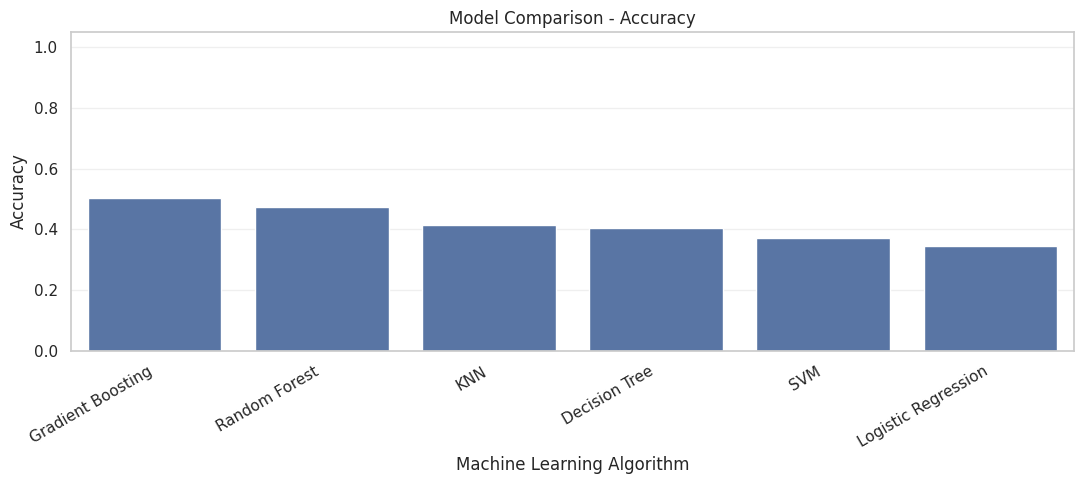

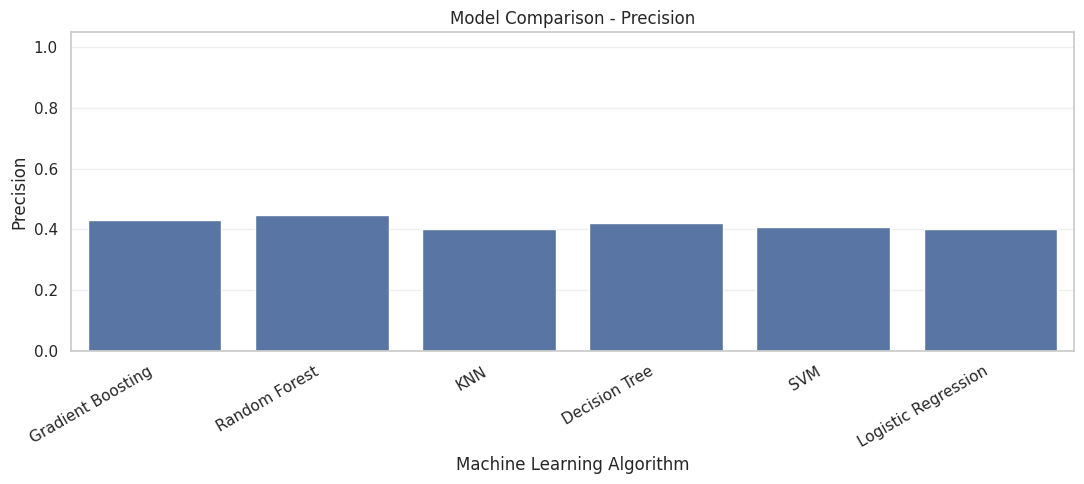

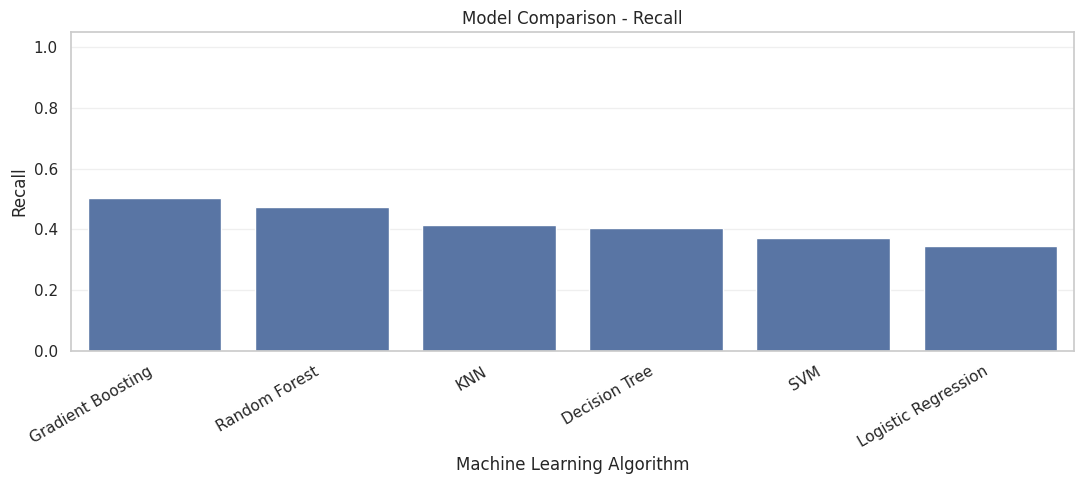

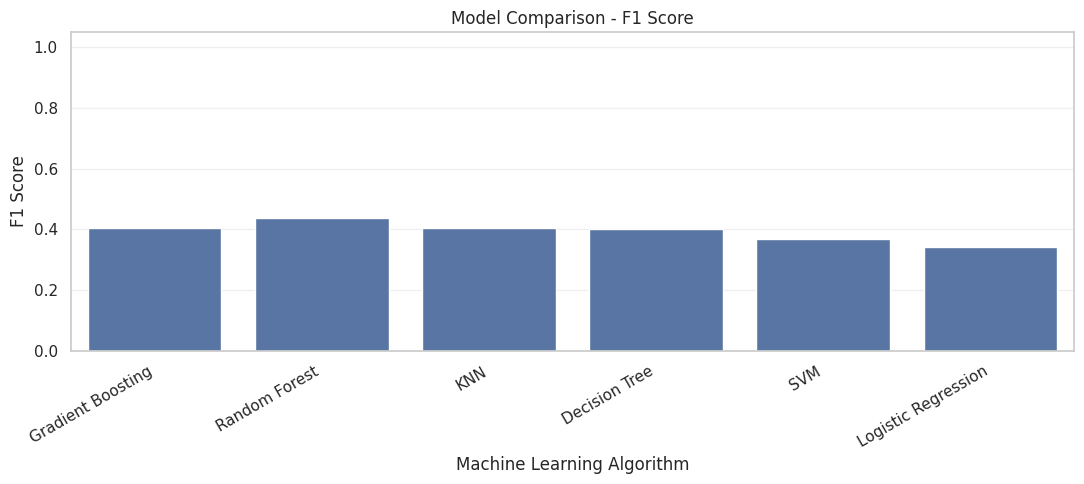

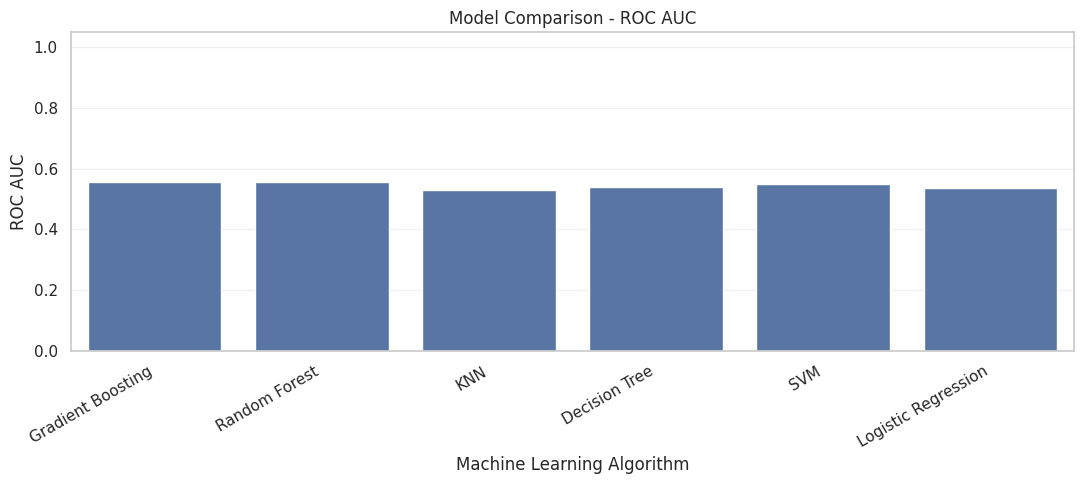

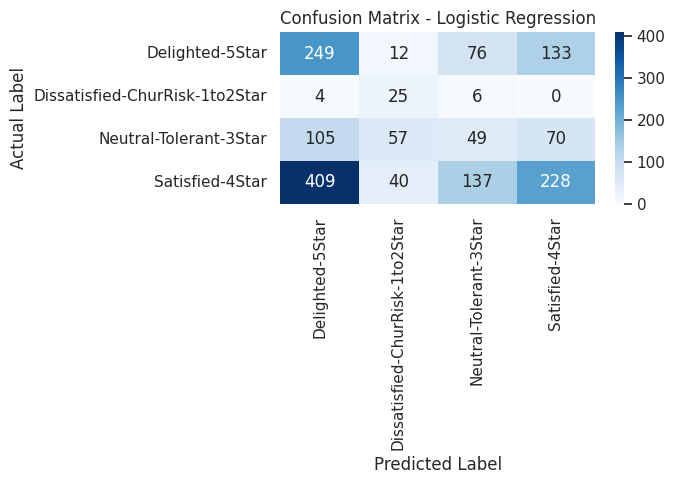

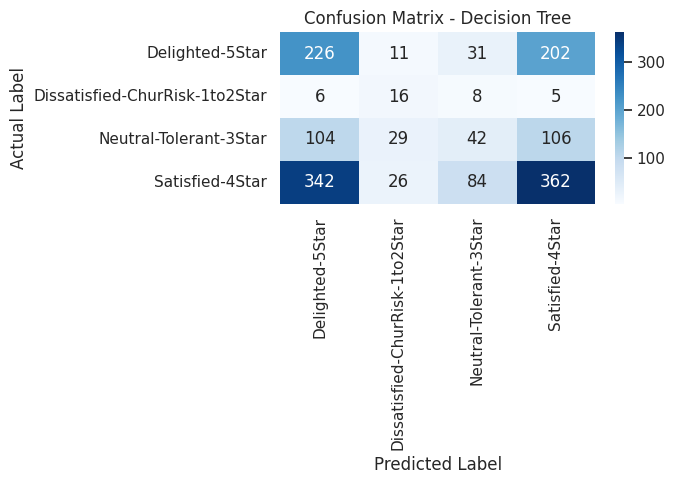

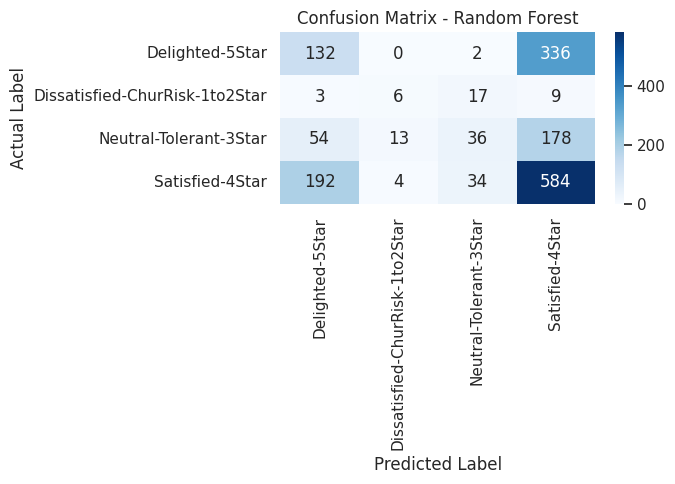

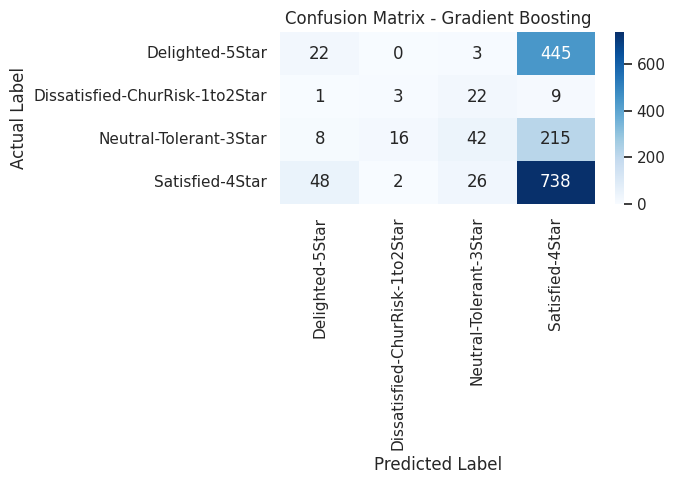

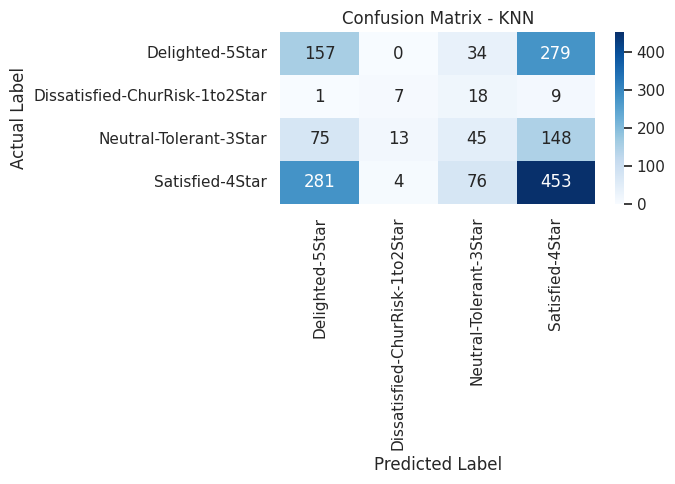

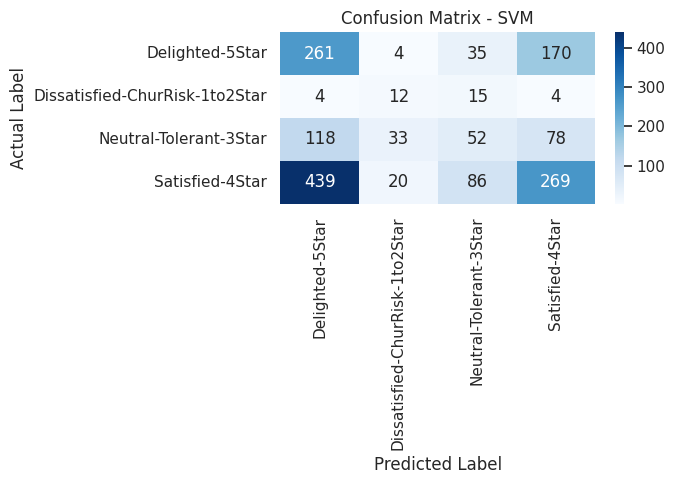

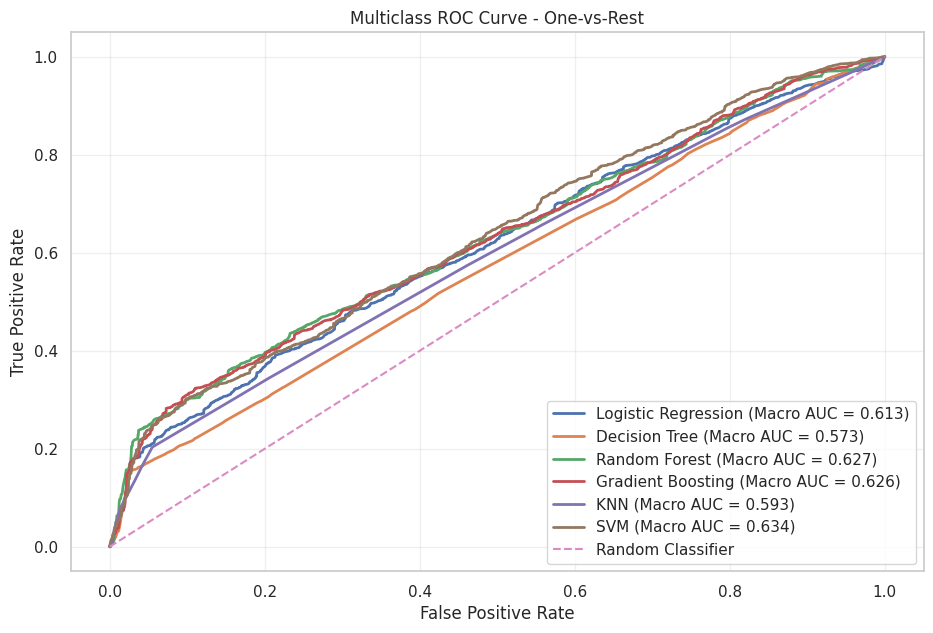


Best Model: Gradient Boosting


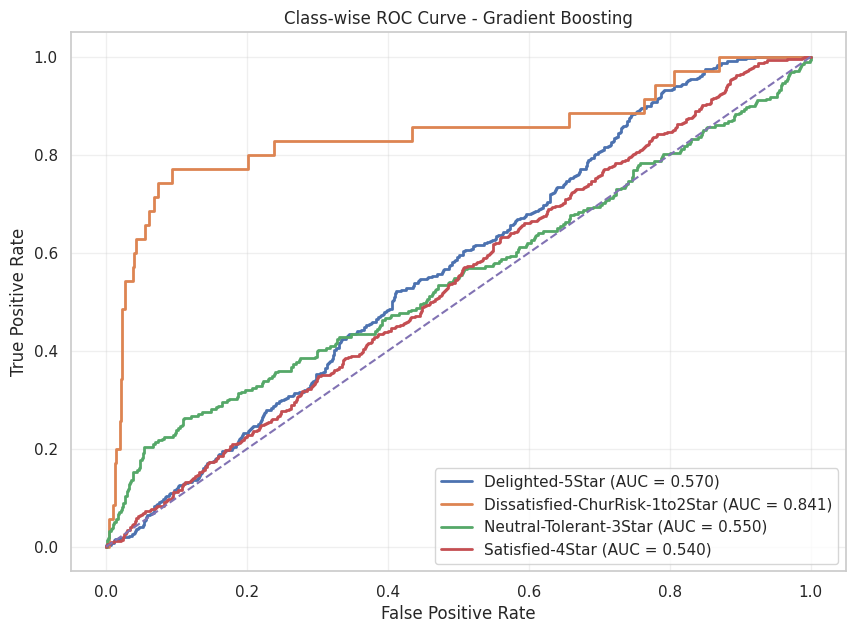

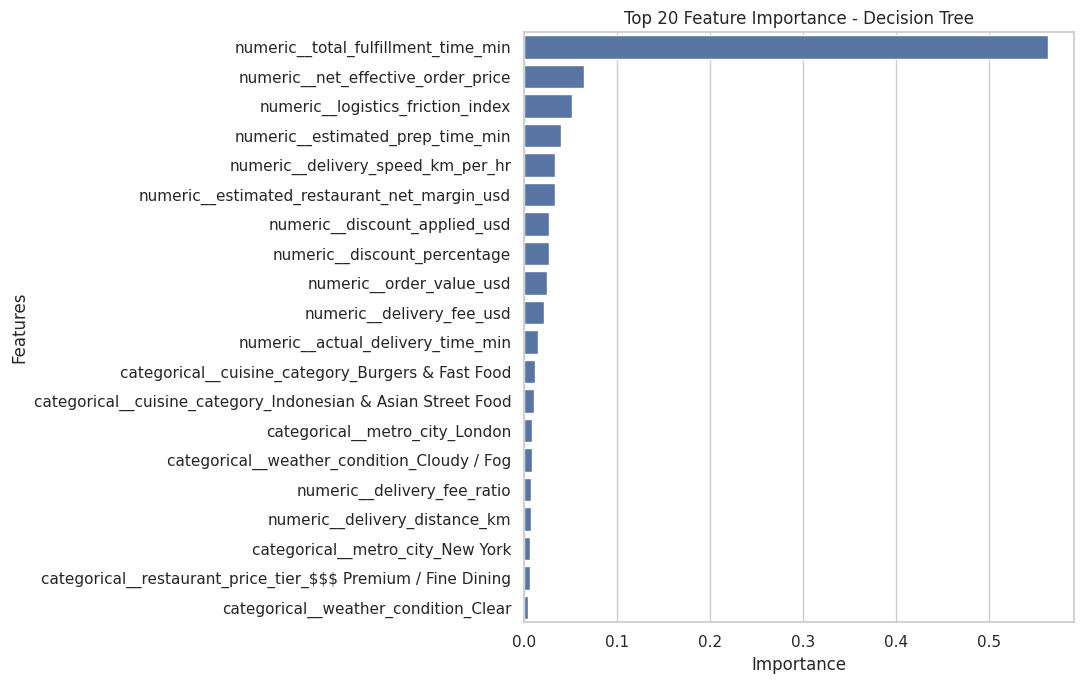

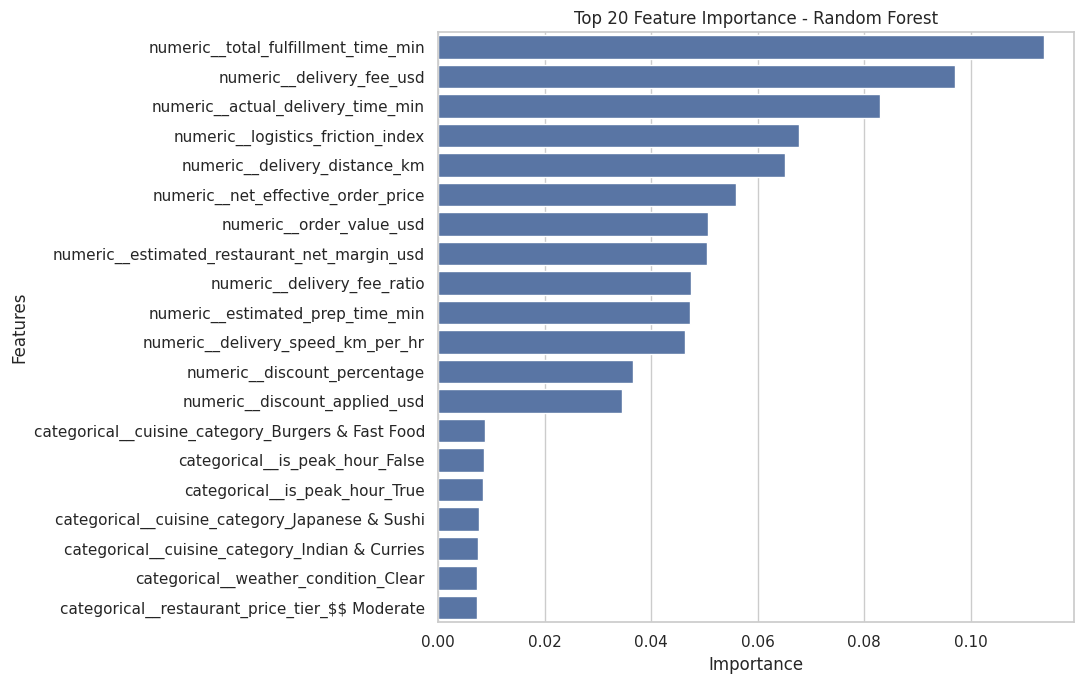


FINAL MODEL RESULTS

Best Model: Gradient Boosting
Best Accuracy: 50.31 %
Best ROC AUC: 0.557

All Model Results:


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Gradient Boosting,0.503125,0.431093,0.503125,0.403429,0.556978
1,Random Forest,0.473750,0.446910,0.473750,0.439158,0.555054
2,KNN,0.413750,0.401028,0.413750,0.404400,0.530471
3,Decision Tree,0.403750,0.419730,0.403750,0.402089,0.540684
4,SVM,0.371250,0.408328,0.371250,0.367699,0.550334
5,Logistic Regression,0.344375,0.400685,0.344375,0.342419,0.536627



ML MODEL TRAINING AND EVALUATION COMPLETED SUCCESSFULLY!


In [14]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, label_binarize
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    roc_auc_score
)

# ================================================================
# 1. LOAD AND INSPECT DATA
# ================================================================

# Your dataset must already be loaded as df.
df = df.copy()

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

# ================================================================
# 2. DATA CLEANING
# ================================================================

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Replace infinite values
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Define target column
target_column = "customer_satisfaction_tier"

if target_column not in df.columns:
    raise ValueError(f"Target column '{target_column}' not found!")

# Remove rows with missing target
df = df.dropna(subset=[target_column])

# Remove leading/trailing spaces from text columns
for col in df.select_dtypes(include=["object", "category"]).columns:
    df[col] = df[col].astype("string").str.strip()

# Convert target to string for consistent label encoding
df[target_column] = df[target_column].astype(str)

print("\nShape After Cleaning:", df.shape)
print("\nTarget Distribution:")
print(df[target_column].value_counts())

# ================================================================
# 3. DEFINE FEATURES AND TARGET
# ================================================================

# Exclude identifiers and columns that could leak target information.
# Review these exclusions against your dataset's actual data definitions.
columns_to_drop = [
    "order_id",
    "customer_rating",
    "primary_satisfaction_driver",
    "confidence_score",
    "cot_market_dynamics_rationale"
]

# Drop only columns that actually exist
columns_to_drop = [
    col for col in columns_to_drop if col in df.columns
]

X = df.drop(columns=[target_column] + columns_to_drop)
y = df[target_column]

print("\nRemoved Columns:", columns_to_drop)
print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)

# Remove constant columns
constant_columns = [
    col for col in X.columns if X[col].nunique(dropna=False) <= 1
]

if constant_columns:
    X.drop(columns=constant_columns, inplace=True)

print("\nConstant Columns Removed:", constant_columns)

# ================================================================
# 4. LABEL ENCODING OF TARGET
# ================================================================

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("\nTarget Label Encoding:")

for original, encoded in zip(
    label_encoder.classes_,
    range(len(label_encoder.classes_))
):
    print(f"{original} = {encoded}")

number_of_classes = len(label_encoder.classes_)

if number_of_classes < 2:
    raise ValueError("Classification requires at least two target classes.")

# ================================================================
# 5. TRAIN-TEST SPLIT
# ================================================================

# Split before fitting feature encoders or scalers.
# Stratification preserves class proportions where possible.

class_counts = pd.Series(y_encoded).value_counts()
stratify_values = y_encoded if class_counts.min() >= 2 else None

if stratify_values is None:
    print("\nWarning: At least one class has fewer than 2 records.")
    print("Using a non-stratified split.")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=stratify_values
)

print("\nTraining Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting Target Distribution:")
print(pd.Series(y_test).value_counts().sort_index())

# ================================================================
# 6. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ================================================================

numeric_features = X_train.select_dtypes(
    include=["int64", "int32", "float64", "float32"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

# Convert boolean columns to categorical values if needed
for col in categorical_features:
    X_train[col] = X_train[col].astype("object")
    X_test[col] = X_test[col].astype("object")

print("\nNumerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

# ================================================================
# 7. FEATURE ENCODING AND SCALING
# ================================================================

# Numerical features:
# Missing value handling + Standard Scaling

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical features:
# Missing value handling + One-Hot Encoding

# Compatibility with different sklearn versions
try:
    categorical_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    )
except TypeError:
    categorical_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=True
    )

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", categorical_encoder)
    ]
)

transformers = []

if numeric_features:
    transformers.append(
        ("numeric", numeric_transformer, numeric_features)
    )

if categorical_features:
    transformers.append(
        ("categorical", categorical_transformer, categorical_features)
    )

if not transformers:
    raise ValueError("No usable numerical or categorical features found.")

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

# ================================================================
# 8. DEFINE MACHINE LEARNING ALGORITHMS
# ================================================================

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "SVM": SVC(
        probability=True,
        class_weight="balanced",
        random_state=42
    )
}

# ================================================================
# 9. TRAIN MODELS AND EVALUATE PERFORMANCE
# ================================================================

results = []
trained_models = {}
predictions = {}
probabilities = {}

for model_name, model in models.items():

    print("\n" + "=" * 65)
    print("Training:", model_name)
    print("=" * 65)

    try:
        # Create complete preprocessing + model pipeline
        pipeline = Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                ("classifier", model)
            ]
        )

        # Train
        pipeline.fit(X_train, y_train)

        # Predict
        y_pred = pipeline.predict(X_test)

        # Predict probabilities for ROC
        y_prob = pipeline.predict_proba(X_test)

        # Evaluation metrics
        accuracy = accuracy_score(y_test, y_pred)

        precision = precision_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        )

        recall = recall_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        )

        f1 = f1_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        )

        # ROC-AUC
        if number_of_classes == 2:
            auc_score = roc_auc_score(
                y_test,
                y_prob[:, 1]
            )
        else:
            auc_score = roc_auc_score(
                y_test,
                y_prob,
                multi_class="ovr",
                average="weighted",
                labels=pipeline.named_steps["classifier"].classes_
            )

        results.append({
            "Model": model_name,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1 Score": f1,
            "ROC AUC": auc_score
        })

        trained_models[model_name] = pipeline
        predictions[model_name] = y_pred
        probabilities[model_name] = y_prob

        print("\nAccuracy:", round(accuracy * 100, 2), "%")
        print("Precision:", round(precision * 100, 2), "%")
        print("Recall:", round(recall * 100, 2), "%")
        print("F1 Score:", round(f1 * 100, 2), "%")
        print("ROC AUC:", round(auc_score, 4))

        print("\nClassification Report:")
        print(
            classification_report(
                y_test,
                y_pred,
                labels=np.arange(number_of_classes),
                target_names=label_encoder.classes_,
                zero_division=0
            )
        )

    except Exception as e:
        print(f"Error while training {model_name}: {e}")

if not results:
    raise RuntimeError("All models failed. Check the dataset and target classes.")

# ================================================================
# 10. MODEL COMPARISON TABLE
# ================================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print("\nMODEL PERFORMANCE COMPARISON")
display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC AUC": "{:.4f}"
    })
)

# ================================================================
# 11. MODEL PERFORMANCE VISUALIZATION
# ================================================================

metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC AUC"
]

for metric in metrics_to_plot:

    plt.figure(figsize=(11, 5))

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric
    )

    plt.title(f"Model Comparison - {metric}")
    plt.ylabel(metric)
    plt.xlabel("Machine Learning Algorithm")
    plt.xticks(rotation=30, ha="right")
    plt.ylim(0, 1.05)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

# ================================================================
# 12. CONFUSION MATRICES FOR ALL MODELS
# ================================================================

for model_name, y_pred in predictions.items():

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(number_of_classes)
    )

    fig, ax = plt.subplots(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
        ax=ax
    )

    ax.set_title(f"Confusion Matrix - {model_name}")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

    plt.tight_layout()
    plt.show()

# ================================================================
# 13. ROC CURVE - BINARY CLASSIFICATION
# ================================================================

if number_of_classes == 2:

    plt.figure(figsize=(10, 7))

    for model_name, y_prob in probabilities.items():

        fpr, tpr, thresholds = roc_curve(
            y_test,
            y_prob[:, 1]
        )

        model_auc = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f"{model_name} (AUC = {model_auc:.3f})"
        )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Random Classifier"
    )

    plt.title("ROC Curve - Binary Classification")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.show()

# ================================================================
# 14. ROC CURVE - MULTICLASS CLASSIFICATION
# ================================================================

else:

    # Macro-average ROC for every model
    plt.figure(figsize=(11, 7))

    y_test_binary = label_binarize(
        y_test,
        classes=np.arange(number_of_classes)
    )

    for model_name, y_prob in probabilities.items():

        fpr_values = {}
        tpr_values = {}
        auc_values = {}

        for i in range(number_of_classes):

            fpr_values[i], tpr_values[i], _ = roc_curve(
                y_test_binary[:, i],
                y_prob[:, i]
            )

            auc_values[i] = auc(
                fpr_values[i],
                tpr_values[i]
            )

        # Build macro-average ROC curve
        all_fpr = np.unique(
            np.concatenate([
                fpr_values[i] for i in range(number_of_classes)
            ])
        )

        mean_tpr = np.zeros_like(all_fpr)

        for i in range(number_of_classes):
            mean_tpr += np.interp(
                all_fpr,
                fpr_values[i],
                tpr_values[i]
            )

        mean_tpr /= number_of_classes

        macro_auc = auc(all_fpr, mean_tpr)

        plt.plot(
            all_fpr,
            mean_tpr,
            linewidth=2,
            label=f"{model_name} (Macro AUC = {macro_auc:.3f})"
        )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Random Classifier"
    )

    plt.title("Multiclass ROC Curve - One-vs-Rest")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.show()

# ================================================================
# 15. ROC CURVE FOR EACH CLASS - BEST MODEL
# ================================================================

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_prob = probabilities[best_model_name]

print("\nBest Model:", best_model_name)

if number_of_classes == 2:

    fpr, tpr, _ = roc_curve(
        y_test,
        best_prob[:, 1]
    )

    plt.figure(figsize=(8, 6))
    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"AUC = {auc(fpr, tpr):.3f}"
    )
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.title(f"ROC Curve - {best_model_name}")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

else:

    y_test_binary = label_binarize(
        y_test,
        classes=np.arange(number_of_classes)
    )

    plt.figure(figsize=(10, 7))

    for i, class_name in enumerate(label_encoder.classes_):

        fpr, tpr, _ = roc_curve(
            y_test_binary[:, i],
            best_prob[:, i]
        )

        class_auc = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f"{class_name} (AUC = {class_auc:.3f})"
        )

    plt.plot([0, 1], [0, 1], linestyle="--")

    plt.title(f"Class-wise ROC Curve - {best_model_name}")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.show()

# ================================================================
# 16. FEATURE IMPORTANCE - TREE-BASED MODELS
# ================================================================

for model_name in ["Decision Tree", "Random Forest"]:

    if model_name not in trained_models:
        continue

    pipeline = trained_models[model_name]

    classifier = pipeline.named_steps["classifier"]
    fitted_preprocessor = pipeline.named_steps["preprocessor"]

    if not hasattr(classifier, "feature_importances_"):
        continue

    feature_names = fitted_preprocessor.get_feature_names_out()

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": classifier.feature_importances_
    })

    importance_df = importance_df.sort_values(
        by="Importance",
        ascending=False
    ).head(20)

    plt.figure(figsize=(11, 7))

    sns.barplot(
        data=importance_df,
        x="Importance",
        y="Feature"
    )

    plt.title(f"Top 20 Feature Importance - {model_name}")
    plt.xlabel("Importance")
    plt.ylabel("Features")
    plt.tight_layout()
    plt.show()

# ================================================================
# 17. FINAL MODEL SUMMARY
# ================================================================

print("\n" + "=" * 65)
print("FINAL MODEL RESULTS")
print("=" * 65)

print("\nBest Model:", best_model_name)

print(
    "Best Accuracy:",
    round(results_df.iloc[0]["Accuracy"] * 100, 2),
    "%"
)

print(
    "Best ROC AUC:",
    round(results_df.iloc[0]["ROC AUC"], 4)
)

print("\nAll Model Results:")
display(results_df)

print("\nML MODEL TRAINING AND EVALUATION COMPLETED SUCCESSFULLY!")


## Thank you..pls upvote!!!!!!!!!!